In [2]:
'''
this notebook will get info about all of the stars included in 
the CNN training data
'''

'\nthis notebook will get info about all of the stars included in \nthe CNN training data\n'

In [1]:
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import os
import pandas as pd
from astropy.wcs import WCS
import shutil
from astroquery.gaia import Gaia
from astropy.coordinates import SkyCoord
import astropy.units as u
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tensorflow import keras

2025-05-29 15:12:06.898871: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
import sys

# adding Folder_2 to the system path
sys.path.insert(0, '/home/3155/rwe')

import review_findings_functions as rff

In [3]:
#matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [4]:
fpath_trans = "/lustre/lrspec/ZTF_data/training_aug24/stamps_pos_trans_2/"
fpath_header = "/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

In [51]:


# List to store dictionaries for DataFrame creation
data_list = []

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    # image_filename_full = os.path.join(image_path, image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = os.path.join(info_path, info_filename)
    print(image_filename)
    quad = image_filename[-12]
    print(quad)
    
    xy_file = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"+image_filename[:-19]+"_"+str(quad)+".fits"
    print(xy_file)
    # Load data
    infos = np.load(info_filename_full)

    # Convert infos to a NumPy array
    infos_arr = np.array(infos)
    
    header_file = fpath_header+image_filename[:-19]+"_"+str(quad)+".wcs"
    print(header_file)
    with fits.open(xy_file) as hdul_xy:
        data = hdul_xy[1].data  
        stored_x = data["X"]  # Column "X"
        stored_y = data["Y"]
        with fits.open(header_file) as hdul_header:
            wcs = WCS(hdul_header[0].header, relax=True)
            # print(hdul_header[0].header.cards)
            # print(wcs)
        # break
        for row in infos_arr:
            target_x = row[2]  # Replace with your x value

            # Find the index of the closest x-coordinate
            closest_idx = np.argmin(np.abs(stored_x - target_x))
            
            # Retrieve the closest (x, y) match
            closest_x, closest_y = stored_x[closest_idx], stored_y[closest_idx]
            # print(closest_x, closest_y )
            # print("Diff:",np.abs(closest_x-target_x))
            
            #get the RA and Dec
            ra, dec = wcs.all_pix2world(closest_x, closest_y, True)
            data_list.append({"filename": image_filename, **dict(enumerate(row)), 
                             "closest_x": closest_x, "closest_y":closest_y, "Diff":np.abs(closest_x-target_x), 
                             "star_ra":ra, "star_dec":dec})



ztf_20221017148750_000831_zi_c01_x_0009._2_stamps.npy
2
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221017148750_000831_zi_c01_x_2.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221017148750_000831_zi_c01_x_2.wcs
ztf_20221014162894_000802_zg_c03_x_0005._3_stamps.npy
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221014162894_000802_zg_c03_x_3.fits


/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221014162894_000802_zg_c03_x_3.wcs
ztf_20220820237546_000798_zr_c13_x_0001._2_stamps.npy
2
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20220820237546_000798_zr_c13_x_2.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20220820237546_000798_zr_c13_x_2.wcs
ztf_20221020138241_000686_zi_c05_x_0028._2_stamps.npy
2
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_2.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020138241_000686_zi_c05_x_2.wcs
ztf_20220820237546_000798_zr_c14_x_0003._2_stamps.npy
2
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20220820237546_000798_zr_c14_x_2.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20220820237546_000798_zr_c14_x_2.wcs
ztf_20221020138241_000686_zi_c01_x_0002._4_stamps.npy
4
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_a

In [52]:
# Create DataFrame
df = pd.DataFrame(data_list)

# Display DataFrame structure
print(df.head())

                                            filename      0    1      2  \
0  ztf_20221017148750_000831_zi_c01_x_0009._2_sta...  0.995  9.0   18.0   
1  ztf_20221017148750_000831_zi_c01_x_0009._2_sta...  0.950  3.0  141.0   
2  ztf_20221017148750_000831_zi_c01_x_0009._2_sta...  0.800  4.0  155.0   
3  ztf_20221017148750_000831_zi_c01_x_0009._2_sta...  0.990  4.0  861.0   
4  ztf_20221017148750_000831_zi_c01_x_0009._2_sta...  0.900  7.0  959.0   

        3  closest_x  closest_y  Diff             star_ra            star_dec  
0   790.0       16.0      698.0   2.0    345.605146563335   59.85300945492153  
1  1507.0      140.0      326.0   1.0   345.5544896710395   59.96027984875607  
2  2718.0      154.0      833.0   1.0   345.5217023287531  59.819103868568746  
3   263.0      860.0     2197.0   1.0  345.06559180549397   59.45352427177412  
4  2001.0      959.0     1618.0   0.0   345.0376703334801  59.619505054585446  


In [ ]:
hdul = fits.open('/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_2.fits')

In [ ]:
hdul2 = fits.open('/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20220820237546_000798_zr_c04_x_4.fits')

In [ ]:
hdul[1].data["X"]

In [ ]:
hdul2[1].data["X"]

In [35]:
df.rename(columns={0: 'intensity', 
                   1: 'sigma',
                  2: 'streak_x_val', 
                   3: 'center_value_y'}, inplace=True)

In [36]:
df

,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec
0,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,4.0,4.0,192.0,1165.0,191.0,698.0,1.0,301.57726087049775,33.043890169246815
1,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,5.0,339.0,907.0,342.0,2705.0,3.0,301.50412499887733,32.480609952350406
2,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,3.0,9.0,344.0,913.0,342.0,2705.0,2.0,301.50412499887733,32.480609952350406
3,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,1.1,4.0,347.0,1244.0,342.0,2705.0,5.0,301.50412499887733,32.480609952350406
4,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,9.0,1161.0,785.0,1159.0,2100.0,2.0,301.2381202913193,32.658573498731585
...,...,...,...,...,...,...,...,...,...,...
9710,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,6.0,1453.0,2064.0,1452.0,2846.0,1.0,301.0640257044031,30.541202360486494
9711,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,3.0,6.0,1560.0,1272.0,1559.0,349.0,1.0,301.0540354591369,31.24333988072323
9712,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,1.3,6.0,1618.0,392.0,1618.0,635.0,0.0,301.03189458172625,31.16378777803424
9713,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,4.0,1759.0,3018.0,1758.0,785.0,1.0,300.9845093851509,31.122945536806707


In [38]:
df.to_csv("/home/3155/training_star_positions")

Text(0.5, 1.0, 'Distance between implantation x value and streak beginning x value')

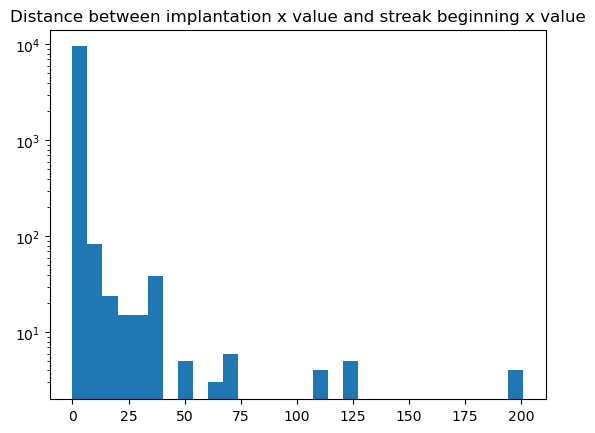

In [25]:
plt.hist(df['Diff'], bins=30)
plt.yscale('log')
np.sum(df['Diff']>8)
plt.title("Distance between implantation x value and streak beginning x value")

In [ ]:
#we have to match all the y coordinates to
#maybe to the list of stars we extracted?


In [54]:
fpath_trans_neg = "/lustre/lrspec/ZTF_data/training_aug24/stamps_neg_trans_2/"
fpath_header = "/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path_neg = fpath_trans_neg + "images/"
info_path_neg = fpath_trans_neg + "info/"

In [57]:


# List to store dictionaries for DataFrame creation
data_list = []

for i, file in enumerate(os.listdir(image_path_neg)):
    image_filename = os.fsdecode(file)
    # image_filename_full = os.path.join(image_path, image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = os.path.join(info_path_neg, info_filename)
    print(image_filename)
    quad = image_filename[-12]
    print(quad)
    
    xy_file = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"+image_filename[:-19]+"_"+str(quad)+".fits"
    print(xy_file)
    # Load data
    infos = np.load(info_filename_full)

    # Convert infos to a NumPy array
    infos_arr = np.array(infos)
    
    header_file = fpath_header+image_filename[:-19]+"_"+str(quad)+".wcs"
    print(header_file)
    with fits.open(xy_file) as hdul_xy:
        data = hdul_xy[1].data  
        stored_x = data["X"]  # Column "X"
        stored_y = data["Y"]
        with fits.open(header_file) as hdul_header:
            wcs = WCS(hdul_header[0].header, relax=True)
            # print(hdul_header[0].header.cards)
            # print(wcs)
        # break
        for row in infos_arr:
            target_x = row[2]  # Replace with your x value

            # Find the index of the closest x-coordinate
            closest_idx = np.argmin(np.abs(stored_x - target_x))
            
            # Retrieve the closest (x, y) match
            closest_x, closest_y = stored_x[closest_idx], stored_y[closest_idx]
            # print(closest_x, closest_y )
            # print("Diff:",np.abs(closest_x-target_x))
            
            #get the RA and Dec
            ra, dec = wcs.all_pix2world(closest_x, closest_y, True)
            data_list.append({"filename": image_filename, **dict(enumerate(row)), 
                             "closest_x": closest_x, "closest_y":closest_y, "Diff":np.abs(closest_x-target_x), 
                             "star_ra":ra, "star_dec":dec})



ztf_20221017148750_000831_zi_c01_x_0009._2_stamps.npy
2
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221017148750_000831_zi_c01_x_2.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221017148750_000831_zi_c01_x_2.wcs
ztf_20221014162894_000802_zg_c03_x_0005._3_stamps.npy
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221014162894_000802_zg_c03_x_3.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221014162894_000802_zg_c03_x_3.wcs
ztf_20220820237546_000798_zr_c13_x_0001._2_stamps.npy
2
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20220820237546_000798_zr_c13_x_2.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20220820237546_000798_zr_c13_x_2.wcs
ztf_20221020138241_000686_zi_c05_x_0028._2_stamps.npy
2
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_2.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_h

ztf_20221014162894_000802_zg_c01_x_0018._4_stamps.npy
4
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221014162894_000802_zg_c01_x_4.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221014162894_000802_zg_c01_x_4.wcs
ztf_20221020138241_000686_zi_c05_x_0023._4_stamps.npy
4
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_4.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020138241_000686_zi_c05_x_4.wcs
ztf_20221020138241_000686_zi_c01_x_0009._2_stamps.npy
2
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c01_x_2.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_headers/ztf_20221020138241_000686_zi_c01_x_2.wcs
ztf_20221020138241_000686_zi_c02_x_0021._4_stamps.npy
4
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c02_x_4.fits
/lustre/lrspec/ZTF_data/corrected_coordinates/new_training_h

In [59]:
# Create DataFrame
df_neg = pd.DataFrame(data_list)

df_neg.rename(columns={0: 'intensity', 
                   1: 'sigma',
                  2: 'streak_x_val', 
                   3: 'center_value_y'}, inplace=True)

# Display DataFrame structure
print(df_neg.head())

                                            filename  intensity  sigma  \
0  ztf_20221017148750_000831_zi_c01_x_0009._2_sta...      0.995    9.0   
1  ztf_20221017148750_000831_zi_c01_x_0009._2_sta...      0.950    3.0   
2  ztf_20221017148750_000831_zi_c01_x_0009._2_sta...      0.800    4.0   
3  ztf_20221017148750_000831_zi_c01_x_0009._2_sta...      0.990    4.0   
4  ztf_20221017148750_000831_zi_c01_x_0009._2_sta...      0.900    7.0   

   streak_x_val  center_value_y  closest_x  closest_y  Diff  \
0          18.0           790.0       16.0      698.0   2.0   
1         141.0          1507.0      140.0      326.0   1.0   
2         155.0          2718.0      154.0      833.0   1.0   
3         861.0           263.0      860.0     2197.0   1.0   
4         959.0          2001.0      959.0     1618.0   0.0   

              star_ra            star_dec  
0    345.605146563335   59.85300945492153  
1   345.5544896710395   59.96027984875607  
2   345.5217023287531  59.819103868568746  


In [63]:
df_neg

,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec
0,ztf_20221017148750_000831_zi_c01_x_0009._2_sta...,0.995,9.0,18.0,790.0,16.0,698.0,2.0,345.605146563335,59.85300945492153
1,ztf_20221017148750_000831_zi_c01_x_0009._2_sta...,0.950,3.0,141.0,1507.0,140.0,326.0,1.0,345.5544896710395,59.96027984875607
2,ztf_20221017148750_000831_zi_c01_x_0009._2_sta...,0.800,4.0,155.0,2718.0,154.0,833.0,1.0,345.5217023287531,59.819103868568746
3,ztf_20221017148750_000831_zi_c01_x_0009._2_sta...,0.990,4.0,861.0,263.0,860.0,2197.0,1.0,345.06559180549397,59.45352427177412
4,ztf_20221017148750_000831_zi_c01_x_0009._2_sta...,0.900,7.0,959.0,2001.0,959.0,1618.0,0.0,345.0376703334801,59.619505054585446
...,...,...,...,...,...,...,...,...,...,...
9710,ztf_20220820237546_000798_zr_c12_x_0004._1_sta...,0.990,5.0,1510.0,397.0,1513.0,2569.0,3.0,275.88011491551964,56.01631403830807
9711,ztf_20220820237546_000798_zr_c12_x_0004._1_sta...,0.850,7.0,1513.0,2016.0,1513.0,2569.0,0.0,275.88011491551964,56.01631403830807
9712,ztf_20220820237546_000798_zr_c12_x_0004._1_sta...,0.850,8.0,1610.0,983.0,1609.0,2153.0,1.0,275.8195475724181,56.13152558889561
9713,ztf_20220820237546_000798_zr_c12_x_0004._1_sta...,0.990,4.0,1667.0,3008.0,1667.0,581.0,0.0,275.7425818543774,56.57263584575158


In [64]:
uniquestars = df_r12.drop_duplicates('gaia_source_id')

In [65]:
uniquestars

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
0,0,0,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,4.00,4.0,192.0,1165.0,191.0,698.0,1.0,301.577261,33.043890,i,2.055162e+18,8.900412,2.5350814,7.744130,10.279211,NOT_AVAILABLE,False
1,1,1,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.00,5.0,339.0,907.0,342.0,2705.0,3.0,301.504125,32.480610,i,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
4,4,4,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.00,9.0,1161.0,785.0,1159.0,2100.0,2.0,301.238120,32.658573,i,2.055125e+18,8.724979,2.4324803,7.605486,10.037967,NOT_AVAILABLE,False
5,5,5,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,10.00,5.0,1537.0,720.0,1535.0,1528.0,2.0,301.118211,32.822502,i,2.055143e+18,7.1805773,1.8194284,6.255091,8.074519,NOT_AVAILABLE,False
6,6,6,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,1.05,7.0,1991.0,1602.0,1991.0,2039.0,0.0,300.960866,32.682556,i,2.031121e+18,9.236366,2.0787315,8.222919,10.301651,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8788,8788,8788,ztf_20220820237546_000798_zr_c14_x_0002._2_sta...,1.10,6.0,2875.0,510.0,2874.0,2295.0,1.0,280.319900,58.063468,r,2.154314e+18,9.244281,0.44295216,8.957750,9.400702,VARIABLE,True
9181,9181,9181,ztf_20221014162894_000802_zg_c02_x_0003._4_sta...,1.01,8.0,1184.0,1882.0,1184.0,2403.0,0.0,326.769132,51.366632,g,1.980802e+18,9.84125,0.71576595,9.394724,10.11049,NOT_AVAILABLE,False
9246,9246,9246,ztf_20220820237546_000798_zr_c12_x_0001._1_sta...,8.00,9.0,2003.0,1540.0,2010.0,297.0,7.0,275.558704,56.646878,r,2.150941e+18,10.1696615,2.2151318,9.107876,11.323008,NOT_AVAILABLE,False
9377,9377,9377,ztf_20221020138241_000686_zi_c06_x_0006._1_sta...,6.00,7.0,2697.0,721.0,2695.0,248.0,2.0,299.551552,33.210761,i,2.034387e+18,8.453409,4.2482405,6.989532,11.237772,VARIABLE,True


In [182]:
to_add=[]
for i, row in df_neg.iterrows():
    fname = row['filename']
    xval = row['closest_x']
    yval = row['closest_y']
    match = df_r12.loc[(df_r12['filename']== fname) & (np.isclose(df_r12['closest_x'],xval))& (np.isclose(df_r12['closest_y'],yval))]
    # if len(match)>1:
    #     match = match.loc
    # print(match['Band'])
    # break
    to_add.append([np.array(match['Band'])[0],np.array(match['gaia_source_id'])[0], np.array(match['rp_mag_ztf_ri'])[0],np.array(match['bp_mag_ztf_g'])[0]])
    

In [183]:
to_add

[['i', 2.0136308934464128e+18, 6.960179805755615, '6.9565372'],
 ['i', 2.013635360212328e+18, 7.956084251403809, '9.527188'],
 ['i', 2.0136303780503404e+18, 6.276890754699707, '9.916788'],
 ['i', 2.0136041959295432e+18, 7.265901565551758, '8.47896'],
 ['i', 2.0136215475973133e+18, 7.754108428955078, '8.948326'],
 ['i', 2.014377530557233e+18, 14.493228912353516, '15.962147'],
 ['i', 2.0142850341417416e+18, 8.459571838378906, '8.451488'],
 ['i', 2.0143045504728005e+18, 7.245806694030762, '7.1655874'],
 ['i', 2.0142742795434796e+18, 8.40440559387207, '10.260316'],
 ['i', 2.014290531699654e+18, 7.761451244354248, '11.289521'],
 ['g', 2.1716995712775416e+18, 9.23619270324707, '9.489899'],
 ['g', 2.1716145996409812e+18, 8.707135200500488, '8.823061'],
 ['g', 2.172466377553981e+18, 9.643319129943848, '9.978847'],
 ['g', 2.172465759071548e+18, 9.029670715332031, '9.483379'],
 ['g', 2.1724656559993464e+18, 8.840851783752441, '9.346131'],
 ['g', 2.1716642151046093e+18, 8.837132453918457, '9.0813

In [185]:
df_neg['Band']=np.array(to_add)[:,0]
df_neg['gaia_source_id']=np.array(to_add)[:,1]
df_neg['rp_mag_ztf_ri']=np.array(to_add)[:,2]
df_neg['bp_mag_ztf_g']=np.array(to_add)[:,3]

In [186]:
df_neg

,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,rp_mag_ztf_ri,bp_mag_ztf_g
0,ztf_20221017148750_000831_zi_c01_x_0009._2_sta...,0.995,9.0,18.0,790.0,16.0,698.0,2.0,345.605146563335,59.85300945492153,i,2.0136308934464128e+18,6.960179805755615,6.9565372
1,ztf_20221017148750_000831_zi_c01_x_0009._2_sta...,0.950,3.0,141.0,1507.0,140.0,326.0,1.0,345.5544896710395,59.96027984875607,i,2.013635360212328e+18,7.956084251403809,9.527188
2,ztf_20221017148750_000831_zi_c01_x_0009._2_sta...,0.800,4.0,155.0,2718.0,154.0,833.0,1.0,345.5217023287531,59.819103868568746,i,2.0136303780503404e+18,6.276890754699707,9.916788
3,ztf_20221017148750_000831_zi_c01_x_0009._2_sta...,0.990,4.0,861.0,263.0,860.0,2197.0,1.0,345.06559180549397,59.45352427177412,i,2.0136041959295432e+18,7.265901565551758,8.47896
4,ztf_20221017148750_000831_zi_c01_x_0009._2_sta...,0.900,7.0,959.0,2001.0,959.0,1618.0,0.0,345.0376703334801,59.619505054585446,i,2.0136215475973133e+18,7.754108428955078,8.948326
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9710,ztf_20220820237546_000798_zr_c12_x_0004._1_sta...,0.990,5.0,1510.0,397.0,1513.0,2569.0,3.0,275.88011491551964,56.01631403830807,r,2.1508934096532485e+18,10.308927536010742,10.787265
9711,ztf_20220820237546_000798_zr_c12_x_0004._1_sta...,0.850,7.0,1513.0,2016.0,1513.0,2569.0,0.0,275.88011491551964,56.01631403830807,r,2.1508934096532485e+18,10.308927536010742,10.787265
9712,ztf_20220820237546_000798_zr_c12_x_0004._1_sta...,0.850,8.0,1610.0,983.0,1609.0,2153.0,1.0,275.8195475724181,56.13152558889561,r,2.1509003116650125e+18,10.008973121643066,10.76014
9713,ztf_20220820237546_000798_zr_c12_x_0004._1_sta...,0.990,4.0,1667.0,3008.0,1667.0,581.0,0.0,275.7425818543774,56.57263584575158,r,2.1509365998444756e+18,10.583711624145508,11.267265


In [48]:
df = pd.read_csv("/home/3155/training_star_positions")

In [61]:
df_r12

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
0,0,0,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,4.0,4.0,192.0,1165.0,191.0,698.0,1.0,301.577261,33.043890,i,2.055162e+18,8.900412,2.5350814,7.744130,10.279211,NOT_AVAILABLE,False
1,1,1,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,5.0,339.0,907.0,342.0,2705.0,3.0,301.504125,32.480610,i,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
2,2,2,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,3.0,9.0,344.0,913.0,342.0,2705.0,2.0,301.504125,32.480610,i,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
3,3,3,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,1.1,4.0,347.0,1244.0,342.0,2705.0,5.0,301.504125,32.480610,i,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
4,4,4,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,9.0,1161.0,785.0,1159.0,2100.0,2.0,301.238120,32.658573,i,2.055125e+18,8.724979,2.4324803,7.605486,10.037967,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9710,9710,9710,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,6.0,1453.0,2064.0,1452.0,2846.0,1.0,301.064026,30.541202,i,2.030590e+18,9.0276165,0.5132394,7.853382,8.366621,NOT_AVAILABLE,False
9711,9711,9711,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,3.0,6.0,1560.0,1272.0,1559.0,349.0,1.0,301.054035,31.243340,i,2.030696e+18,6.8288445,0.34999084,6.597105,6.947096,NOT_AVAILABLE,False
9712,9712,9712,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,1.3,6.0,1618.0,392.0,1618.0,635.0,0.0,301.031895,31.163788,i,2.030695e+18,9.009199,1.258398,8.301562,9.55996,NOT_AVAILABLE,False
9713,9713,9713,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,4.0,1759.0,3018.0,1758.0,785.0,1.0,300.984509,31.122946,i,2.030693e+18,7.8214054,-0.04813814,7.837292,7.7891536,NOT_AVAILABLE,False


In [55]:
def query_gaia_for_stars(df, radius=5):
    """
    Query Gaia DR3 to match stars in the given DataFrame based on RA and Dec.
    Adds Gaia source ID, magnitude (G, BP-RP, RP, BP), and variability information.
    Additionally checks if the star is listed in the Gaia DR3 vari_summary table.
    
    Parameters:
        df (pd.DataFrame): DataFrame with 'ra' and 'dec' columns.
        radius (float): Search radius in arcseconds.
        
    Returns:
        pd.DataFrame: Updated DataFrame with Gaia data.
    """
    gaia_columns = [
        'source_id', 'ra', 'dec', 'phot_g_mean_mag', 'bp_rp', 'phot_rp_mean_mag', 'phot_bp_mean_mag', 'phot_variable_flag'
    ]
    
    new_data = []
    
    for _, row in df.iterrows():
        coord = SkyCoord(ra=row['star_ra']*u.deg, dec=row['star_dec']*u.deg, frame='icrs')
        
        query = f"""
        SELECT TOP 1 {', '.join(gaia_columns)} FROM gaiadr3.gaia_source
        WHERE CONTAINS(POINT('ICRS', ra, dec), 
                       CIRCLE('ICRS', {row['star_ra']}, {row['star_dec']}, {radius}/3600.0))=1
        ORDER BY phot_g_mean_mag ASC
        """
        
        job = Gaia.launch_job(query)
        results = job.get_results()
        
        if len(results) > 0:
            best_match = results[0]
            source_id = best_match['source_id']
            
            # Check if the star is in the vari_summary table
            var_query = f"""
            SELECT COUNT(*) AS var_count FROM gaiadr3.vari_summary
            WHERE source_id = {source_id}
            """
            var_job = Gaia.launch_job(var_query)
            var_results = var_job.get_results()
            is_variable = var_results['var_count'][0] > 0
            
            new_data.append([
                source_id, best_match['phot_g_mean_mag'],
                best_match['bp_rp'], best_match['phot_rp_mean_mag'],
                best_match['phot_bp_mean_mag'], best_match['phot_variable_flag'],
                is_variable
            ])
        else:
            new_data.append([None, None, None, None, None, None, None])
    
    df[['gaia_source_id', 'g_mag', 'bp_rp', 'r_mag', 'i_mag', 'variability', 'in_vari_summary']] = new_data
    return df

       ra     dec gaia_source_id g_mag bp_rp r_mag i_mag variability
0  10.684  41.269           None  None  None  None  None        None
1  83.822  -5.391           None  None  None  None  None        None


In [56]:
# df = query_gaia_for_stars(df)
# df.to_csv("/home/3155/training_star_info")

   Unnamed: 0                                           filename  intensity  \
0           0  ztf_20221020138241_000686_zi_c05_x_0011._2_sta...       4.00   
1           1  ztf_20221020138241_000686_zi_c05_x_0011._2_sta...       8.00   
2           2  ztf_20221020138241_000686_zi_c05_x_0011._2_sta...       3.00   
3           3  ztf_20221020138241_000686_zi_c05_x_0011._2_sta...       1.10   
4           4  ztf_20221020138241_000686_zi_c05_x_0011._2_sta...       8.00   
5           5  ztf_20221020138241_000686_zi_c05_x_0011._2_sta...      10.00   
6           6  ztf_20221020138241_000686_zi_c05_x_0011._2_sta...       1.05   
7           7  ztf_20221020138241_000686_zi_c05_x_0011._2_sta...       1.30   
8           8  ztf_20221020138241_000686_zi_c05_x_0011._2_sta...       1.30   
9           9  ztf_20221020138241_000686_zi_c05_x_0011._2_sta...       1.05   

   sigma  streak_x_val  center_value_y  closest_x  closest_y  Diff  \
0    4.0         192.0          1165.0      191.0      698.0

In [24]:
df_r12= pd.read_csv("/home/3155/training_star_info_r12")
band = []
for i in range(len(df_r12)):
    band.append(df_r12.loc[i]['filename'][27])
df_r12["Band"] = band
df_r12_diffclean = df_r12[df_r12["Diff"]<9]

In [25]:
df_r12_diffclean

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,gaia_source_id,g_mag,bp_rp,r_mag,i_mag,variability,in_vari_summary,Band
0,0,0,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,4.0,4.0,192.0,1165.0,191.0,698.0,1.0,301.577261,33.043890,2.055162e+18,8.900412,2.5350814,7.744130,10.279211,NOT_AVAILABLE,False,i
1,1,1,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,5.0,339.0,907.0,342.0,2705.0,3.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False,i
2,2,2,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,3.0,9.0,344.0,913.0,342.0,2705.0,2.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False,i
3,3,3,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,1.1,4.0,347.0,1244.0,342.0,2705.0,5.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False,i
4,4,4,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,9.0,1161.0,785.0,1159.0,2100.0,2.0,301.238120,32.658573,2.055125e+18,8.724979,2.4324803,7.605486,10.037967,NOT_AVAILABLE,False,i
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9710,9710,9710,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,6.0,1453.0,2064.0,1452.0,2846.0,1.0,301.064026,30.541202,2.030590e+18,8.729559,0.5058465,7.863333,8.36918,NOT_AVAILABLE,False,i
9711,9711,9711,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,3.0,6.0,1560.0,1272.0,1559.0,349.0,1.0,301.054035,31.243340,2.030696e+18,6.8288445,0.34999084,6.597105,6.947096,NOT_AVAILABLE,False,i
9712,9712,9712,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,1.3,6.0,1618.0,392.0,1618.0,635.0,0.0,301.031895,31.163788,2.030695e+18,9.009199,1.258398,8.301562,9.55996,NOT_AVAILABLE,False,i
9713,9713,9713,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,4.0,1759.0,3018.0,1758.0,785.0,1.0,300.984509,31.122946,2.030693e+18,7.8214054,-0.04813814,7.837292,7.7891536,NOT_AVAILABLE,False,i


In [18]:
df_r12.loc[100]['filename'][27]

'r'

In [318]:
np.sum(pd.to_numeric(df_r12[df_r12["Diff"]<9]['g_mag'], 'coerce')>15)

230

In [8]:
np.sum(pd.to_numeric(df_r16[df_r16["Diff"]<9]['g_mag'], 'coerce')>15)

242

Text(0.5, 1.0, 'g magnitude of stars in training streaks (log)')

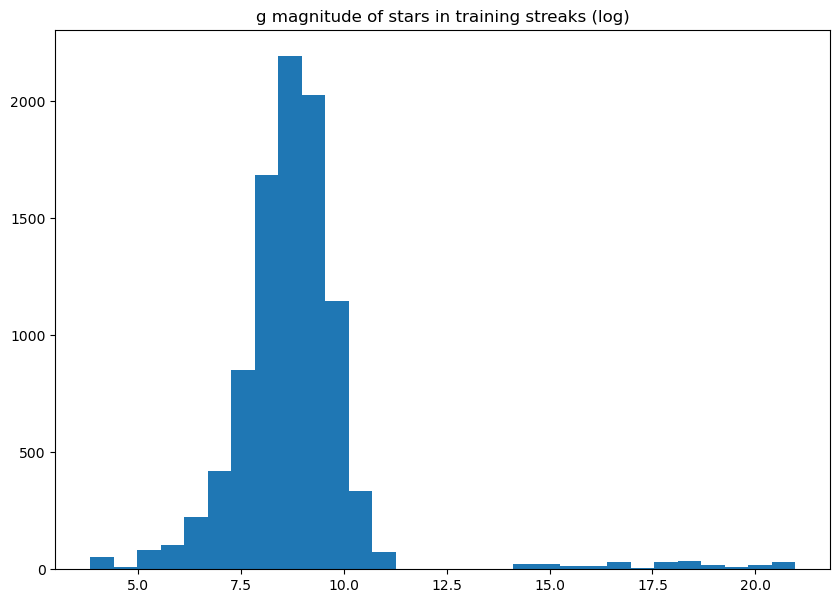

In [7]:
plt.hist(pd.to_numeric(df_r12[df_r12["Diff"]<9]['g_mag'], 'coerce'),bins=30)
plt.title("g magnitude of stars in training streaks (log)")
# plt.yscale("log")


In [287]:
np.sum(pd.to_numeric(df_r9['g_mag'], 'coerce')>15)

387

In [25]:
df_r12= pd.read_csv("/home/3155/training_star_info_r12")

In [6]:
np.sum(pd.to_numeric(df_r16['g_mag'], 'coerce')>15)

243

Text(0.5, 1.0, 'g magnitude of stars in training streaks (log)')

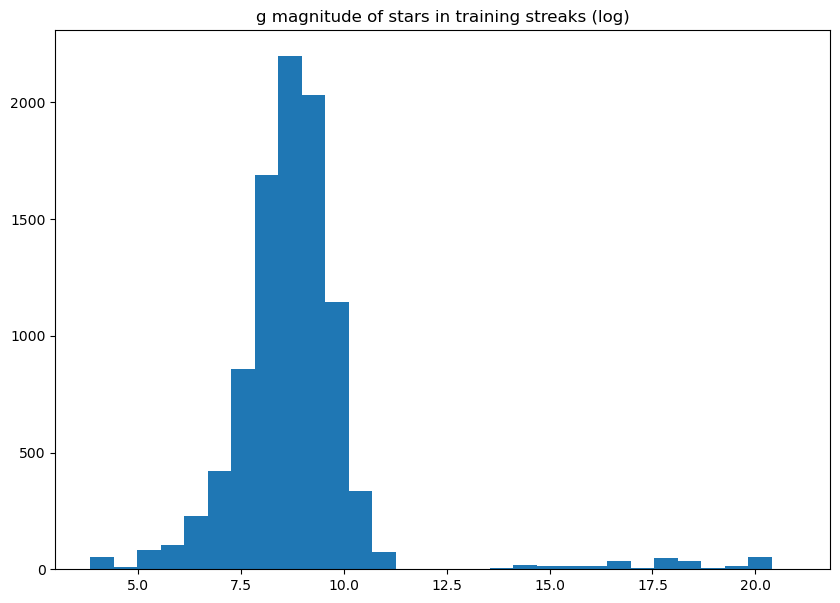

In [7]:
plt.hist(pd.to_numeric(df_r16[df_r16["Diff"]<9]['g_mag'], 'coerce'),bins=30)
plt.title("g magnitude of stars in training streaks (log)")

In [77]:
df_r9

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,gaia_source_id,g_mag,bp_rp,r_mag,i_mag,variability,in_vari_summary
0,0,0,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,4.0,4.0,192.0,1165.0,191.0,698.0,1.0,301.577261,33.043890,2.055162e+18,8.900412,2.5350814,7.744130,10.279211,NOT_AVAILABLE,False
1,1,1,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,5.0,339.0,907.0,342.0,2705.0,3.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
2,2,2,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,3.0,9.0,344.0,913.0,342.0,2705.0,2.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
3,3,3,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,1.1,4.0,347.0,1244.0,342.0,2705.0,5.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
4,4,4,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,9.0,1161.0,785.0,1159.0,2100.0,2.0,301.238120,32.658573,2.055125e+18,8.724979,2.4324803,7.605486,10.037967,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9710,9710,9710,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,6.0,1453.0,2064.0,1452.0,2846.0,1.0,301.064026,30.541202,2.030590e+18,8.729559,0.5058465,7.863333,8.36918,NOT_AVAILABLE,False
9711,9711,9711,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,3.0,6.0,1560.0,1272.0,1559.0,349.0,1.0,301.054035,31.243340,2.030696e+18,6.8288445,0.34999084,6.597105,6.947096,NOT_AVAILABLE,False
9712,9712,9712,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,1.3,6.0,1618.0,392.0,1618.0,635.0,0.0,301.031895,31.163788,2.030695e+18,9.009199,1.258398,8.301562,9.55996,NOT_AVAILABLE,False
9713,9713,9713,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,4.0,1759.0,3018.0,1758.0,785.0,1.0,300.984509,31.122946,2.030693e+18,7.8214054,-0.04813814,7.837292,7.7891536,NOT_AVAILABLE,False


In [119]:
df_r9["filename"][0]

'ztf_20221020138241_000686_zi_c05_x_0011._2_stamps.npy'

In [76]:
df_r9 = df_r9.dropna()

In [78]:
np.sum(df_r9['in_vari_summary']==True)

1199

In [88]:
np.sum(df_r9['Diff']>12)

156

In [98]:
df_r9_clean = df_r9.drop((df_r9[df_r9['Diff']>8]).index, axis=0)

In [99]:
df_r9_clean

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,gaia_source_id,g_mag,bp_rp,r_mag,i_mag,variability,in_vari_summary
0,0,0,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,4.0,4.0,192.0,1165.0,191.0,698.0,1.0,301.577261,33.043890,2.055162e+18,8.900412,2.5350814,7.744130,10.279211,NOT_AVAILABLE,False
1,1,1,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,5.0,339.0,907.0,342.0,2705.0,3.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
2,2,2,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,3.0,9.0,344.0,913.0,342.0,2705.0,2.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
3,3,3,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,1.1,4.0,347.0,1244.0,342.0,2705.0,5.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
4,4,4,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,9.0,1161.0,785.0,1159.0,2100.0,2.0,301.238120,32.658573,2.055125e+18,8.724979,2.4324803,7.605486,10.037967,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9710,9710,9710,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,6.0,1453.0,2064.0,1452.0,2846.0,1.0,301.064026,30.541202,2.030590e+18,8.729559,0.5058465,7.863333,8.36918,NOT_AVAILABLE,False
9711,9711,9711,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,3.0,6.0,1560.0,1272.0,1559.0,349.0,1.0,301.054035,31.243340,2.030696e+18,6.8288445,0.34999084,6.597105,6.947096,NOT_AVAILABLE,False
9712,9712,9712,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,1.3,6.0,1618.0,392.0,1618.0,635.0,0.0,301.031895,31.163788,2.030695e+18,9.009199,1.258398,8.301562,9.55996,NOT_AVAILABLE,False
9713,9713,9713,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,4.0,1759.0,3018.0,1758.0,785.0,1.0,300.984509,31.122946,2.030693e+18,7.8214054,-0.04813814,7.837292,7.7891536,NOT_AVAILABLE,False


In [113]:
df_r9_clean[pd.to_numeric(df_r9_clean['g_mag'], 'coerce')>15].index

Int64Index([   9,   81,   85,   90,  119,  146,  150,  196,  221,  249,
            ...
            9416, 9441, 9460, 9479, 9514, 9530, 9598, 9599, 9659, 9702],
           dtype='int64', length=385)

In [115]:
df_r9_clean[df_r9_clean['g_mag']=='--'].index

Int64Index([ 569,  867, 1120, 1396, 1802, 2493, 2630, 3256, 3769, 4245, 4906,
            6105, 6920, 7379, 7870, 8031, 8702, 9003, 9633],
           dtype='int64')

Text(0.5, 0, 'g-band magnitude')

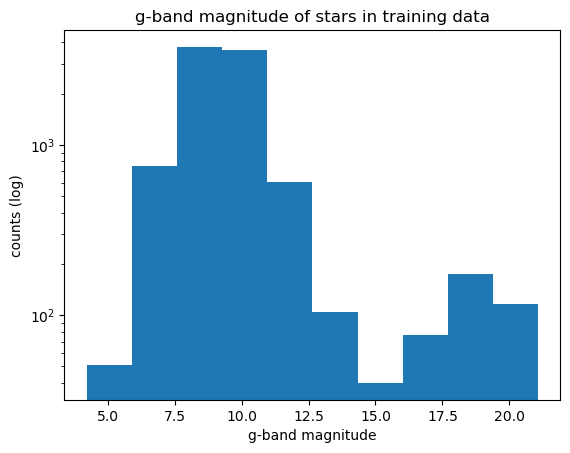

In [118]:
plt.hist(pd.to_numeric(df_r9_clean['i_mag'], 'coerce'))
plt.yscale('log')
plt.title("g-band magnitude of stars in training data")
plt.ylabel("counts (log)")
plt.xlabel("g-band magnitude")

In [100]:
df_r9_clean.infer_objects().dtypes

Unnamed: 0.1         int64
Unnamed: 0           int64
filename            object
intensity          float64
sigma              float64
streak_x_val       float64
center_value_y     float64
closest_x          float64
closest_y          float64
Diff               float64
star_ra            float64
star_dec           float64
gaia_source_id     float64
g_mag               object
bp_rp               object
r_mag              float64
i_mag               object
variability         object
in_vari_summary       bool
dtype: object

In [93]:
df_r9.dtypes

Unnamed: 0.1         int64
Unnamed: 0           int64
filename            object
intensity          float64
sigma              float64
streak_x_val       float64
center_value_y     float64
closest_x          float64
closest_y          float64
Diff               float64
star_ra            float64
star_dec           float64
gaia_source_id     float64
g_mag               object
bp_rp               object
r_mag              float64
i_mag               object
variability         object
in_vari_summary     object
dtype: object

(array([42., 23., 15.,  0.,  4., 29., 21.,  0.,  0.,  0.,  5.,  0.,  0.,
         3.,  0.,  0.,  6.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         4.,  0.,  0.,  0.,  5.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  4.]),
 array([ 12.  ,  15.78,  19.56,  23.34,  27.12,  30.9 ,  34.68,  38.46,
         42.24,  46.02,  49.8 ,  53.58,  57.36,  61.14,  64.92,  68.7 ,
         72.48,  76.26,  80.04,  83.82,  87.6 ,  91.38,  95.16,  98.94,
        102.72, 106.5 , 110.28, 114.06, 117.84, 121.62, 125.4 , 129.18,
        132.96, 136.74, 140.52, 144.3 , 148.08, 151.86, 155.64, 159.42,
        163.2 , 166.98, 170.76, 174.54, 178.32, 182.1 , 185.88, 189.66,
        193.44, 197.22, 201.  ]),
 <BarContainer object of 50 artists>)

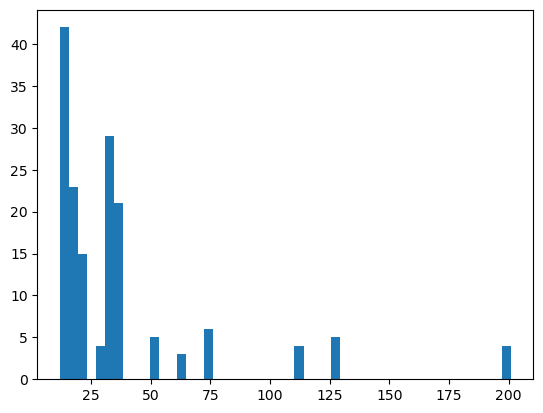

In [84]:
plt.hist(df_r9['Diff'][df_r9['Diff']>8], bins=50)


In [72]:
# np.save("/home/3155/training_star_info_partial", np.array([1,2,3]))

In [73]:
# np.load("/home/3155/training_star_info_partial.npy")

array([1, 2, 3])

In [121]:
df_r9_clean

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,gaia_source_id,g_mag,bp_rp,r_mag,i_mag,variability,in_vari_summary
0,0,0,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,4.0,4.0,192.0,1165.0,191.0,698.0,1.0,301.577261,33.043890,2.055162e+18,8.900412,2.5350814,7.744130,10.279211,NOT_AVAILABLE,False
1,1,1,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,5.0,339.0,907.0,342.0,2705.0,3.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
2,2,2,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,3.0,9.0,344.0,913.0,342.0,2705.0,2.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
3,3,3,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,1.1,4.0,347.0,1244.0,342.0,2705.0,5.0,301.504125,32.480610,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
4,4,4,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,9.0,1161.0,785.0,1159.0,2100.0,2.0,301.238120,32.658573,2.055125e+18,8.724979,2.4324803,7.605486,10.037967,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9710,9710,9710,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,6.0,1453.0,2064.0,1452.0,2846.0,1.0,301.064026,30.541202,2.030590e+18,8.729559,0.5058465,7.863333,8.36918,NOT_AVAILABLE,False
9711,9711,9711,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,3.0,6.0,1560.0,1272.0,1559.0,349.0,1.0,301.054035,31.243340,2.030696e+18,6.8288445,0.34999084,6.597105,6.947096,NOT_AVAILABLE,False
9712,9712,9712,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,1.3,6.0,1618.0,392.0,1618.0,635.0,0.0,301.031895,31.163788,2.030695e+18,9.009199,1.258398,8.301562,9.55996,NOT_AVAILABLE,False
9713,9713,9713,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,4.0,1759.0,3018.0,1758.0,785.0,1.0,300.984509,31.122946,2.030693e+18,7.8214054,-0.04813814,7.837292,7.7891536,NOT_AVAILABLE,False


In [181]:
df_r9[pd.to_numeric(df_r9['g_mag'], 'coerce')>15].index

Int64Index([   9,   81,   85,   90,  119,  146,  150,  196,  221,  249,
            ...
            9416, 9441, 9460, 9479, 9514, 9530, 9598, 9599, 9659, 9702],
           dtype='int64', length=387)

In [267]:
df_r9_clean[110:125]

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,gaia_source_id,g_mag,bp_rp,r_mag,i_mag,variability,in_vari_summary
119,119,119,ztf_20221020138241_000686_zi_c06_x_0013._1_sta...,1.50,4.0,1306.0,1934.0,1304.0,1482.0,2.0,300.011406,32.854494,2.034166e+18,15.523178,2.8500862,14.286480,17.136566,NOT_AVAILABLE,False
120,120,120,ztf_20221020138241_000686_zi_c06_x_0013._1_sta...,6.00,8.0,1335.0,2817.0,1334.0,2959.0,1.0,299.992716,32.438596,2.034102e+18,8.155191,1.2226973,7.466134,8.688831,NOT_AVAILABLE,False
121,121,121,ztf_20221020138241_000686_zi_c06_x_0013._1_sta...,1.05,6.0,1641.0,2086.0,1640.0,1337.0,1.0,299.899791,32.897245,2.034177e+18,7.511455,-0.14337015,7.592959,7.449589,NOT_AVAILABLE,False
122,122,122,ztf_20221020138241_000686_zi_c06_x_0013._1_sta...,2.00,9.0,1749.0,442.0,1748.0,1470.0,1.0,299.862861,32.860268,2.034176e+18,8.399642,1.1708927,7.734107,8.905,NOT_AVAILABLE,False
123,123,123,ztf_20221020138241_000686_zi_c06_x_0013._1_sta...,1.30,7.0,1771.0,1039.0,1769.0,2609.0,2.0,299.849659,32.539381,2.034151e+18,8.587931,2.9044547,7.346007,10.250462,VARIABLE,True
124,124,124,ztf_20220820237546_000798_zr_c12_x_0000._1_sta...,1.05,9.0,71.0,1116.0,70.0,418.0,1.0,276.553246,56.641118,2.151117e+18,8.87091,1.1796637,8.199564,9.379228,NOT_AVAILABLE,False
126,126,126,ztf_20220820237546_000798_zr_c12_x_0000._1_sta...,8.00,5.0,502.0,1892.0,502.0,2267.0,0.0,276.380839,56.116597,2.150733e+18,11.054776,1.0731297,10.425111,11.49824,NOT_AVAILABLE,False
127,127,127,ztf_20220820237546_000798_zr_c12_x_0000._1_sta...,1.30,5.0,579.0,1707.0,578.0,2740.0,1.0,276.354760,55.982920,2.150709e+18,10.737892,1.2146025,10.054138,11.268741,NOT_AVAILABLE,False
128,128,128,ztf_20220820237546_000798_zr_c12_x_0000._1_sta...,1.50,6.0,1356.0,1623.0,1355.0,2469.0,1.0,275.956669,56.046999,2.150712e+18,10.165428,1.0951967,9.538320,10.633516,NOT_AVAILABLE,False
129,129,129,ztf_20220820237546_000798_zr_c12_x_0000._1_sta...,4.00,8.0,1510.0,1273.0,1513.0,2569.0,3.0,275.880115,56.016314,2.150893e+18,10.614105,0.4783373,10.308928,10.787265,NOT_AVAILABLE,False


In [152]:
print(df_r9_clean['filename'].loc[81][8:12])

1020


In [144]:
stamps = np.load(image_path+df_r9_clean['filename'][9])
stamps_81 = np.load(image_path+df_r9_clean['filename'].loc[81])

In [271]:
df.loc[1]["filename"][:-19] + ".fits.fz"

'ztf_20221020138241_000686_zi_c05_x.fits.fz'

In [5]:
def get_image_from_training_df(df, index):

    """
    returns image, stamp, background
    and a 20x20 numpy array of brightnesses centered around the detection
    located at index of dataframe df
    note that the filepath to the science images is hardcoded currently
    """
    fname = df.loc[index]["filename"][:-14] + ".fits.fz"
    col = int(df.loc[index]["streak_x_val"])
    row = int(df.loc[index]["center_value_y"])
    quad = int(df.loc[index]["filename"][-12])
    direcname = df.loc[index]["filename"][8:12]
    fname_beginning = df.loc[index]["filename"][:-19] + ".fits.fz"
    fpath = (
        "/lustre/lrspec/ZTF_data/2022/"
        + direcname
        + "/"
    )
    # else:
    # fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"/"
    path = fpath + fname
    hdul = fits.open(path)
    file1_array = hdul[quad].data
    stamp = file1_array[row - 10 : row + 10, col - 10 : col + 10]
    # plt.imshow(stamp)
    # plt.colorbar()
    background = rff.get_image_background(file1_array)
    beginning_fits = fits.open(fpath+fname_beginning)
    beginning_image = beginning_fits[quad].data
    return file1_array, stamp, background,beginning_image

In [205]:
maxes = []
# for index in df_r9[pd.to_numeric(df_r9['g_mag'], 'coerce')>15].index:
for index in df_r9[pd.to_numeric(df_r9['g_mag'], 'coerce')<15].index:
    file1_array, stamp, background = get_image_from_training_df(df_r9_clean, index)
    maxes.append(np.max(stamp))
    if len(maxes)>50:
        break

In [204]:
maxes_dim = []
for index in df_r9[pd.to_numeric(df_r9['g_mag'], 'coerce')>15].index:
    file1_array, stamp, background = get_image_from_training_df(df_r9, index)
    maxes_dim.append(np.max(stamp))
    if len(maxes_dim)>50:
        break

In [242]:
file1_array, stamp, background = get_image_from_training_df(df_r9, 9)

In [260]:
df_r9[81:95]

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,gaia_source_id,g_mag,bp_rp,r_mag,i_mag,variability,in_vari_summary
81,81,81,ztf_20221020138241_000686_zi_c02_x_0013._2_sta...,1.30,9.0,2150.0,3016.0,2149.0,2542.0,1.0,298.683450,30.657437,2.033421e+18,17.342564,1.5262375,16.496479,18.022717,NOT_AVAILABLE,False
82,82,82,ztf_20221020138241_000686_zi_c03_x_0001._4_sta...,1.10,3.0,181.0,1886.0,180.0,370.0,1.0,298.178722,30.370136,2.033390e+18,8.214967,2.0885625,7.196617,9.285179,NOT_AVAILABLE,False
83,83,83,ztf_20221020138241_000686_zi_c03_x_0001._4_sta...,1.05,4.0,225.0,213.0,224.0,1528.0,1.0,298.163285,30.044515,2.033375e+18,8.549378,1.9143114,7.589816,9.5041275,NOT_AVAILABLE,False
84,84,84,ztf_20221020138241_000686_zi_c03_x_0001._4_sta...,10.00,6.0,574.0,445.0,573.0,2492.0,1.0,298.049175,29.774413,2.028867e+18,9.255154,2.4091682,8.150124,10.559292,NOT_AVAILABLE,False
85,85,85,ztf_20221020138241_000686_zi_c03_x_0001._4_sta...,10.00,5.0,2482.0,2192.0,2482.0,2696.0,0.0,297.430607,29.719082,2.031854e+18,20.063797,2.271988,18.547525,20.819513,NOT_AVAILABLE,False
86,86,86,ztf_20221020138241_000686_zi_c03_x_0001._4_sta...,10.00,7.0,2595.0,2377.0,2594.0,2182.0,1.0,297.393884,29.862729,2.031860e+18,7.964323,0.43822622,7.680787,8.119013,NOT_AVAILABLE,False
87,87,87,ztf_20221020138241_000686_zi_c03_x_0001._4_sta...,1.05,5.0,2701.0,779.0,2701.0,499.0,0.0,297.357283,30.333925,2.031953e+18,8.702245,1.2803054,7.989850,9.270155,NOT_AVAILABLE,False
88,88,88,ztf_20221020138241_000686_zi_c03_x_0001._4_sta...,2.00,4.0,2870.0,758.0,2870.0,225.0,0.0,297.301770,30.410763,2.031957e+18,9.217063,5.649844,7.664946,13.31479,VARIABLE,True
89,89,89,ztf_20221020138241_000686_zi_c03_x_0001._4_sta...,1.30,8.0,2895.0,1183.0,2894.0,101.0,1.0,297.293750,30.445551,2.031958e+18,8.753339,2.2792177,7.678260,9.957478,NOT_AVAILABLE,False
90,90,90,ztf_20221020138241_000686_zi_c03_x_0001._4_sta...,1.10,9.0,3001.0,875.0,3000.0,2092.0,1.0,297.261951,29.888126,2.031907e+18,19.524572,1.4853706,18.162056,19.647427,NOT_AVAILABLE,False


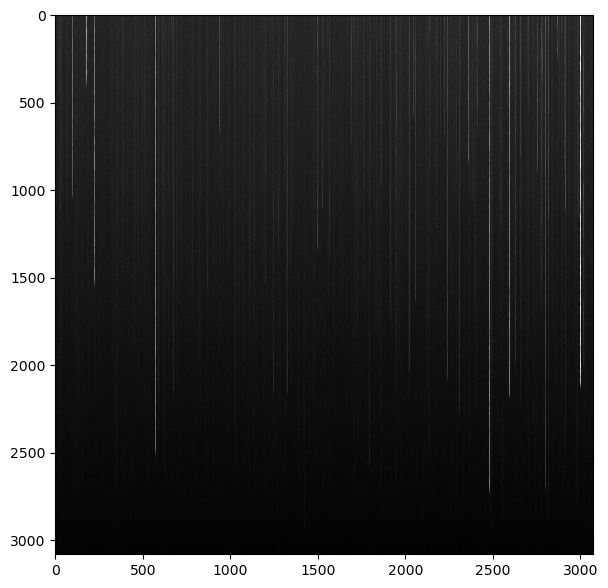

In [278]:
plt.imshow(np.sqrt(beginning_image))

Text(2870.0, 25.0, '9 magnitude 9')

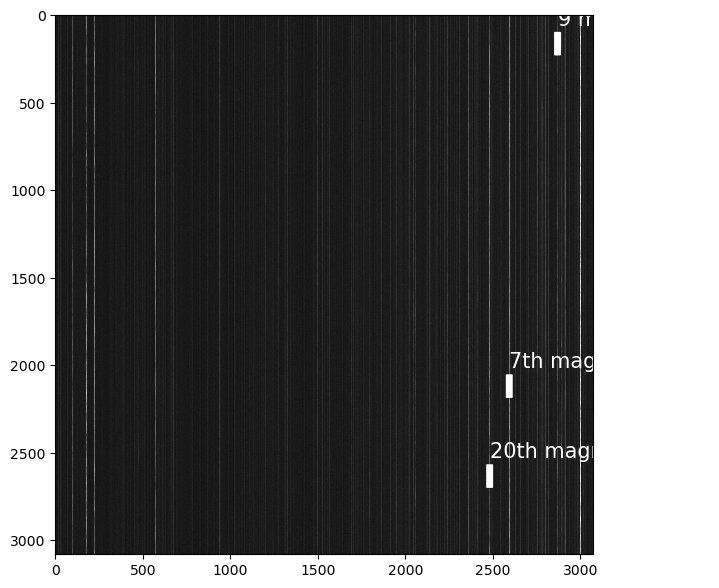

In [291]:
file1_array, stamp, background, beginning_image = get_image_from_training_df(df_r9, 86)

index = 86
plt.imshow(np.sqrt(file1_array))
plt.annotate(
    "7th magnitude 7",
    xy=(df_r9['closest_x'][index], df_r9['closest_y'][index]),
    xytext=(df_r9['closest_x'][index], df_r9['closest_y'][index]-200),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=15,
    va="center",
    zorder=1,
)
index=85
plt.annotate(
    "20th magnitude 20",
    xy=(df_r9['closest_x'][index], df_r9['closest_y'][index]),
    xytext=(df_r9['closest_x'][index], df_r9['closest_y'][index]-200),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=15,
    va="center",
    zorder=1,
)

index = 88
plt.imshow(np.sqrt(file1_array))
plt.annotate(
    "9 magnitude 9",
    xy=(df_r9['closest_x'][index], df_r9['closest_y'][index]),
    xytext=(df_r9['closest_x'][index], df_r9['closest_y'][index]-200),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=15,
    va="center",
    zorder=1,
)

Text(2870.0, 25.0, '9 magnitude 9')

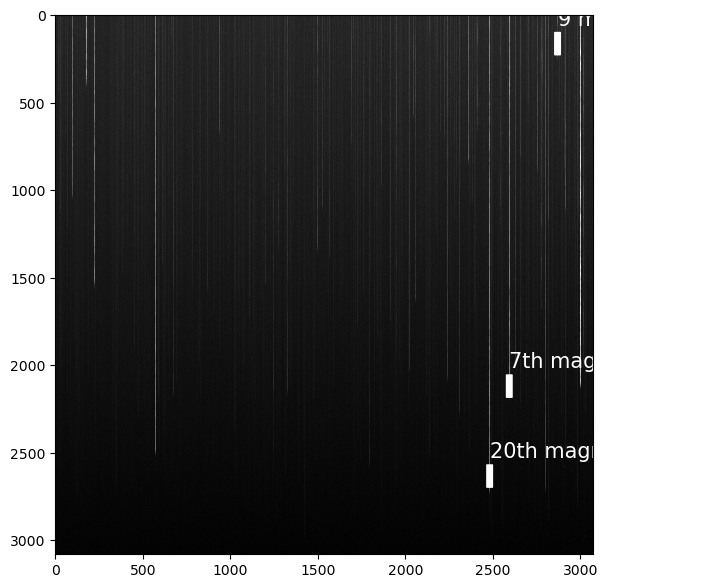

In [293]:
plt.imshow(np.sqrt(beginning_image))
index=86
plt.annotate(
    "7th magnitude 7",
    xy=(df_r9['closest_x'][index], df_r9['closest_y'][index]),
    xytext=(df_r9['closest_x'][index], df_r9['closest_y'][index]-200),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=15,
    va="center",
    zorder=1,
)
index=85
plt.annotate(
    "20th magnitude 20",
    xy=(df_r9['closest_x'][index], df_r9['closest_y'][index]),
    xytext=(df_r9['closest_x'][index], df_r9['closest_y'][index]-200),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=15,
    va="center",
    zorder=1,
)

index = 88
plt.annotate(
    "9 magnitude 9",
    xy=(df_r9['closest_x'][index], df_r9['closest_y'][index]),
    xytext=(df_r9['closest_x'][index], df_r9['closest_y'][index]-200),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=15,
    va="center",
    zorder=1,
)

Text(2164.0, 90.0, 'magnitude 7')

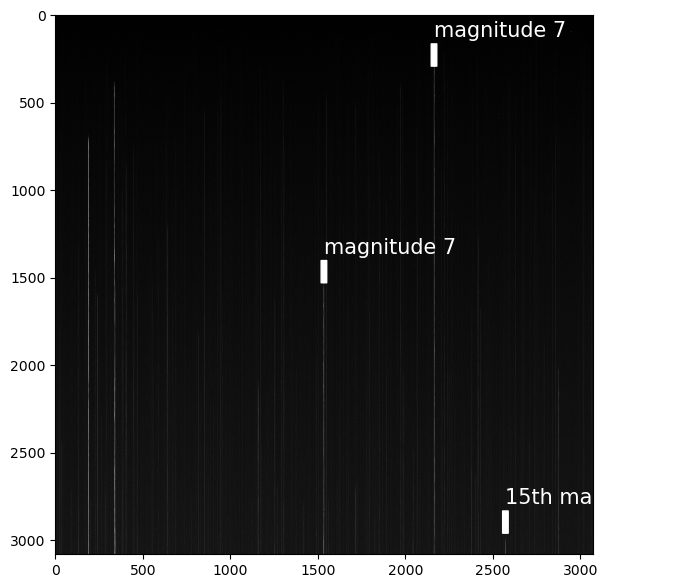

In [294]:
file1_array, stamp, background,beginning = get_image_from_training_df(df_r9, 9)
index = 5
plt.imshow(np.sqrt(beginning))
plt.annotate(
    "magnitude 7",
    xy=(df_r9['closest_x'][index], df_r9['closest_y'][index]),
    xytext=(df_r9['closest_x'][index], df_r9['closest_y'][index]-200),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=15,
    va="center",
    zorder=1,
)
index=9
plt.annotate(
    "15th magnitude",
    xy=(df_r9['closest_x'][index], df_r9['closest_y'][index]),
    xytext=(df_r9['closest_x'][index], df_r9['closest_y'][index]-200),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=15,
    va="center",
    zorder=1,
)

index = 7
plt.annotate(
    "magnitude 7",
    xy=(df_r9['closest_x'][index], df_r9['closest_y'][index]),
    xytext=(df_r9['closest_x'][index], df_r9['closest_y'][index]-200),  # make it 358 eventually
    arrowprops=dict(
        facecolor="white",
        edgecolor="white",
        shrink=0.0,
        headlength=0.001,
        headwidth=0.001,
    ),
    color="white",
    fontsize=15,
    va="center",
    zorder=1,
)

In [213]:
np.max(maxes)

6365.565

In [214]:
np.max(maxes_dim)

4977.4194

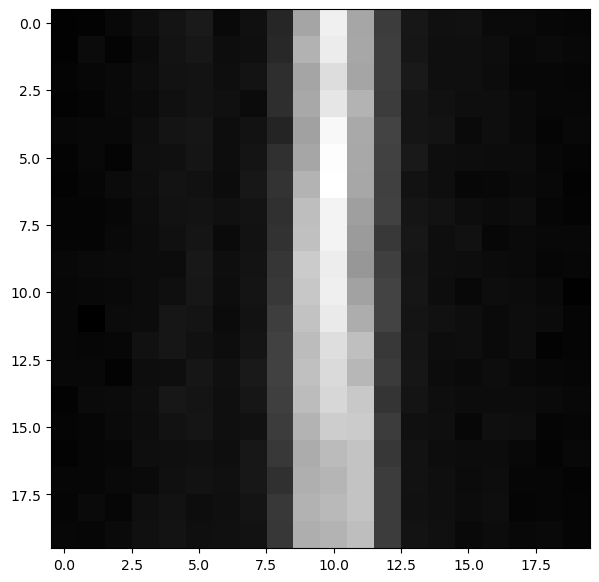

In [145]:
plt.imshow(stamps[9])
plt.imshow(stamps_81[9])

In [218]:
df_tr, df_te = train_test_split(df_r9, random_state=302)

In [219]:
df_tedf_te

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,gaia_source_id,g_mag,bp_rp,r_mag,i_mag,variability,in_vari_summary
4669,4669,4669,ztf_20221014162894_000802_zg_c01_x_0021._1_sta...,1.3,9.0,1608.0,2805.0,1608.0,1444.0,0.0,329.685833,52.437593,1.981232e+18,9.418205,0.259717,9.242564,9.502281,NOT_AVAILABLE,False
1609,1609,1609,ztf_20221020138241_000686_zi_c05_x_0023._3_sta...,1.1,9.0,1126.0,91.0,1125.0,615.0,1.0,301.232081,32.178300,2.031046e+18,8.510672,1.2197561,7.823135,9.0428915,NOT_AVAILABLE,False
5456,5456,5456,ztf_20221017148750_000831_zi_c05_x_0008._4_sta...,2.0,7.0,282.0,833.0,281.0,2916.0,1.0,347.257303,60.161321,2.013981e+18,8.315317,0.74695826,7.855259,8.602218,NOT_AVAILABLE,False
2929,2929,2929,ztf_20221017148750_000831_zi_c02_x_0026._3_sta...,8.0,4.0,2266.0,1132.0,2264.0,2654.0,2.0,340.610851,58.525766,2.008162e+18,7.9199877,0.18035984,7.789752,7.970112,NOT_AVAILABLE,False
861,861,861,ztf_20220820237546_000798_zr_c07_x_0001._3_sta...,4.0,3.0,2378.0,2928.0,2378.0,216.0,0.0,277.351298,53.897794,2.148932e+18,10.20622,1.1469212,9.553129,10.70005,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8912,8912,8912,ztf_20221014162894_000802_zg_c02_x_0009._3_sta...,4.0,3.0,1600.0,1632.0,1599.0,2638.0,1.0,325.196920,51.324712,2.171490e+18,8.204575,0.65035677,7.797674,8.44803,NOT_AVAILABLE,False
3626,3626,3626,ztf_20221020138241_000686_zi_c01_x_0028._4_sta...,1.1,3.0,2300.0,850.0,2299.0,2487.0,1.0,301.756255,29.723374,2.029733e+18,17.050322,1.7372227,16.108271,17.845493,NOT_AVAILABLE,False
3257,3257,3257,ztf_20221017148750_000831_zi_c04_x_0010._3_sta...,1.1,7.0,2699.0,1908.0,2698.0,1580.0,1.0,333.240985,58.657927,2.199603e+18,9.942679,3.151226,8.669956,11.821182,NOT_AVAILABLE,False
8110,8110,8110,ztf_20220820237546_000798_zr_c04_x_0004._3_sta...,8.0,5.0,2836.0,1498.0,2836.0,1701.0,0.0,274.289223,51.461424,2.124400e+18,8.838137,1.3365297,8.103482,9.440012,NOT_AVAILABLE,False


In [6]:
fpath_streak = "/lustre/lrspec/ZTF_data/training_aug24/stamps_no_trans/images/"


for i, file in enumerate(os.listdir(fpath_streak)):
    image_filename = os.fsdecode(file)
    image_filename_full = fpath_streak + image_filename
    print(image_filename)
    streak = np.load(image_filename_full)
    streak_arr = np.array(streak)
    print(np.shape(streak))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_streak_stamps = streak_arr
    else:
        all_streak_stamps = np.concatenate((all_streak_stamps, streak_arr), axis=0)

ztf_20221017148750_000831_zi_c02_x_0026._4_stamps.npy
(7, 20, 20)
ztf_20221014162894_000802_zg_c01_x_0014._2_stamps.npy
(8, 20, 20)
ztf_20221017148750_000831_zi_c03_x_0018._3_stamps.npy
(4, 20, 20)
ztf_20220820237546_000798_zr_c14_x_0004._2_stamps.npy
(10, 20, 20)
ztf_20221014162894_000802_zg_c01_x_0021._1_stamps.npy
(10, 20, 20)
ztf_20221020138241_000686_zi_c01_x_0005._4_stamps.npy
(9, 20, 20)
ztf_20221017148750_000831_zi_c03_x_0001._1_stamps.npy
(7, 20, 20)
ztf_20221020138241_000686_zi_c02_x_0001._3_stamps.npy
(10, 20, 20)
ztf_20221020138241_000686_zi_c06_x_0007._4_stamps.npy
(10, 20, 20)
ztf_20221020138241_000686_zi_c07_x_0020._1_stamps.npy
(9, 20, 20)
ztf_20221014162894_000802_zg_c03_x_0002._3_stamps.npy
(6, 20, 20)
ztf_20220820237546_000798_zr_c02_x_0002._3_stamps.npy
(10, 20, 20)
ztf_20221014162894_000802_zg_c02_x_0023._2_stamps.npy
(5, 20, 20)
ztf_20221020138241_000686_zi_c03_x_0015._1_stamps.npy
(9, 20, 20)
ztf_20221014162894_000802_zg_c02_x_0016._1_stamps.npy
(8, 20, 20)
ztf_2

In [10]:
np.shape(all_streak_stamps)

(9715, 20, 20)

In [7]:
fpath_trans = "/lustre/lrspec/ZTF_data/training_aug24/stamps_pos_trans_2/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_pos_stamps = trans_arr
        all_pos_stamps_info = infos_arr
    else:
        all_pos_stamps = np.concatenate((all_pos_stamps, trans_arr), axis=0)
        all_pos_stamps_info = np.concatenate((all_pos_stamps_info, infos_arr), axis=0)

ztf_20221020138241_000686_zi_c05_x_0011._2_stamps.npy
(10, 20, 20)
(10, 4)
ztf_20220820237546_000798_zr_c04_x_0000._4_stamps.npy
(9, 20, 20)
(9, 4)
ztf_20221017148750_000831_zi_c03_x_0026._3_stamps.npy
(4, 20, 20)
(4, 4)
ztf_20221020138241_000686_zi_c02_x_0026._1_stamps.npy
(10, 20, 20)
(10, 4)
ztf_20221014162894_000802_zg_c02_x_0002._4_stamps.npy
(7, 20, 20)
(7, 4)
ztf_20221014162894_000802_zg_c03_x_0010._2_stamps.npy
(6, 20, 20)
(6, 4)
ztf_20220820237546_000798_zr_c07_x_0004._3_stamps.npy
(10, 20, 20)
(10, 4)
ztf_20221017148750_000831_zi_c04_x_0008._2_stamps.npy
(8, 20, 20)
(8, 4)
ztf_20220820237546_000798_zr_c16_x_0000._2_stamps.npy
(8, 20, 20)
(8, 4)
ztf_20221020138241_000686_zi_c02_x_0013._2_stamps.npy
(10, 20, 20)
(10, 4)
ztf_20221020138241_000686_zi_c03_x_0001._4_stamps.npy
(9, 20, 20)
(9, 4)
ztf_20221014162894_000802_zg_c02_x_0028._1_stamps.npy
(8, 20, 20)
(8, 4)
ztf_20220820237546_000798_zr_c09_x_0000._3_stamps.npy
(10, 20, 20)
(10, 4)
ztf_20221017148750_000831_zi_c04_x_0017._

In [12]:
np.shape(all_pos_stamps)

(9715, 20, 20)

In [13]:
np.shape(all_pos_stamps)

(9715, 20, 20)

In [8]:
fpath_cr = "/lustre/lrspec/ZTF_data/training_aug24/stamps_cr/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

for i, file in enumerate(os.listdir(fpath_cr)):
    image_filename = os.fsdecode(file)
    image_filename_full = fpath_cr + image_filename
    print(image_filename)
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    print(np.shape(trans))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_cr_stamps = trans
    else:
        all_cr_stamps = np.concatenate((all_cr_stamps, trans_arr), axis=0)

cr_1017.npy
(150, 20, 20)
cr_1014.npy
(150, 20, 20)
cr_0820.npy
(150, 20, 20)
cr_1020.npy
(150, 20, 20)


In [15]:
np.shape(all_cr_stamps)

(600, 20, 20)

In [9]:
fpath_trans = "/lustre/lrspec/ZTF_data/training_aug24/stamps_neg_trans_2/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_neg_stamps = trans_arr
        all_neg_stamps_info = infos_arr
    else:
        all_neg_stamps = np.concatenate((all_neg_stamps, trans_arr), axis=0)
        all_neg_stamps_info = np.concatenate((all_neg_stamps_info, infos_arr), axis=0)

ztf_20221017148750_000831_zi_c01_x_0009._2_stamps.npy
(10, 20, 20)
(10, 4)
ztf_20221014162894_000802_zg_c03_x_0005._3_stamps.npy
(6, 20, 20)
(6, 4)
ztf_20220820237546_000798_zr_c13_x_0001._2_stamps.npy
(7, 20, 20)
(7, 4)
ztf_20221020138241_000686_zi_c05_x_0028._2_stamps.npy
(10, 20, 20)
(10, 4)
ztf_20220820237546_000798_zr_c14_x_0003._2_stamps.npy
(10, 20, 20)
(10, 4)
ztf_20221020138241_000686_zi_c01_x_0002._4_stamps.npy
(9, 20, 20)
(9, 4)
ztf_20221017148750_000831_zi_c02_x_0021._4_stamps.npy
(7, 20, 20)
(7, 4)
ztf_20220820237546_000798_zr_c01_x_0001._4_stamps.npy
(10, 20, 20)
(10, 4)
ztf_20221014162894_000802_zg_c01_x_0013._2_stamps.npy
(8, 20, 20)
(8, 4)
ztf_20221020138241_000686_zi_c01_x_0028._1_stamps.npy
(10, 20, 20)
(10, 4)
ztf_20221014162894_000802_zg_c02_x_0011._1_stamps.npy
(8, 20, 20)
(8, 4)
ztf_20221014162894_000802_zg_c02_x_0008._3_stamps.npy
(9, 20, 20)
(9, 4)
ztf_20221017148750_000831_zi_c04_x_0009._3_stamps.npy
(6, 20, 20)
(6, 4)
ztf_20221014162894_000802_zg_c03_x_0011._

In [17]:
np.shape(all_neg_stamps)

(9715, 20, 20)

In [10]:
fpath_bg = "/lustre/lrspec/ZTF_data/training_aug24/stamps_background/images/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

for i, file in enumerate(os.listdir(fpath_bg)):
    image_filename = os.fsdecode(file)
    image_filename_full = fpath_bg + image_filename
    print(image_filename)
    bg = np.load(image_filename_full)
    bg_arr = np.array(bg)
    print(np.shape(bg))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_bg_stamps = bg
    else:
        all_bg_stamps = np.concatenate((all_bg_stamps, bg_arr), axis=0)

    # all_trans_stamps[i] = trans
# neg_stamps = all_bg_stamps

ztf_20221014162894_000802_zg_c02_x_0002._4_background_stamps.npy
(18, 20, 20)
ztf_20221014162894_000802_zg_c01_x_0029._1_background_stamps.npy
(23, 20, 20)
ztf_20220820237546_000798_zr_c07_x_0002._4_background_stamps.npy
(25, 20, 20)
ztf_20220820237546_000798_zr_c13_x_0001._4_background_stamps.npy
(17, 20, 20)
ztf_20221020138241_000686_zi_c01_x_0009._1_background_stamps.npy
(23, 20, 20)
ztf_20221014162894_000802_zg_c02_x_0003._2_background_stamps.npy
(22, 20, 20)
ztf_20220820237546_000798_zr_c07_x_0003._2_background_stamps.npy
(29, 20, 20)
ztf_20220820237546_000798_zr_c14_x_0002._3_background_stamps.npy
(20, 20, 20)
ztf_20221017148750_000831_zi_c04_x_0007._1_background_stamps.npy
(32, 20, 20)
ztf_20221020138241_000686_zi_c05_x_0021._3_background_stamps.npy
(20, 20, 20)
ztf_20221020138241_000686_zi_c07_x_0017._3_background_stamps.npy
(24, 20, 20)
ztf_20221017148750_000831_zi_c02_x_0017._4_background_stamps.npy
(25, 20, 20)
ztf_20220820237546_000798_zr_c02_x_0004._3_background_stamps.npy

In [19]:
np.shape(all_bg_stamps)

(24382, 20, 20)

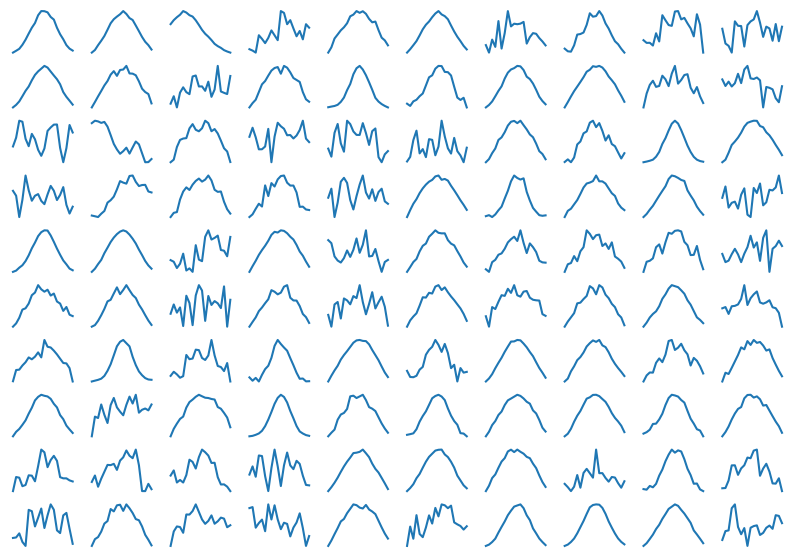

In [20]:
fig, ax = plt.subplots(10, 10)
for i in range(10):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(all_pos_stamps[i * 10 + h], axis=1))
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        ax[i, h].axis("off")
fig.show()

In [21]:
all_pos_stamps_info[:, 0]

array([4. , 8. , 3. , ..., 1.3, 2. , 1.3])

In [12]:
df_r12 = pd.read_csv('/home/3155/training_star_info_r12_bands')

In [50]:
df_r12

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
0,0,0,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,4.0,4.0,192.0,1165.0,191.0,698.0,1.0,301.577261,33.043890,i,2.055162e+18,8.900412,2.5350814,7.744130,10.279211,NOT_AVAILABLE,False
1,1,1,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,5.0,339.0,907.0,342.0,2705.0,3.0,301.504125,32.480610,i,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
2,2,2,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,3.0,9.0,344.0,913.0,342.0,2705.0,2.0,301.504125,32.480610,i,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
3,3,3,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,1.1,4.0,347.0,1244.0,342.0,2705.0,5.0,301.504125,32.480610,i,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
4,4,4,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,8.0,9.0,1161.0,785.0,1159.0,2100.0,2.0,301.238120,32.658573,i,2.055125e+18,8.724979,2.4324803,7.605486,10.037967,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9710,9710,9710,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,6.0,1453.0,2064.0,1452.0,2846.0,1.0,301.064026,30.541202,i,2.030590e+18,9.0276165,0.5132394,7.853382,8.366621,NOT_AVAILABLE,False
9711,9711,9711,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,3.0,6.0,1560.0,1272.0,1559.0,349.0,1.0,301.054035,31.243340,i,2.030696e+18,6.8288445,0.34999084,6.597105,6.947096,NOT_AVAILABLE,False
9712,9712,9712,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,1.3,6.0,1618.0,392.0,1618.0,635.0,0.0,301.031895,31.163788,i,2.030695e+18,9.009199,1.258398,8.301562,9.55996,NOT_AVAILABLE,False
9713,9713,9713,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,2.0,4.0,1759.0,3018.0,1758.0,785.0,1.0,300.984509,31.122946,i,2.030693e+18,7.8214054,-0.04813814,7.837292,7.7891536,NOT_AVAILABLE,False


In [86]:
df_zeros = df_r12.applymap(lambda x: 0)

In [102]:
feature_list = df_r12.columns
df_zeros_bg = pd.DataFrame(0, index=np.arange(len(all_bg_stamps)), columns=feature_list) 
df_zeros_cr = pd.DataFrame(0, index=np.arange(len(all_cr_stamps)), columns=feature_list) 

In [101]:
all_bg_stamps.shape

(24382, 20, 20)

In [107]:
df_streaks = df_r12.copy()
df_streaks['intensity'] = np.zeros(len(df_streaks))
df_streaks['sigma'] = np.zeros(len(df_streaks))

In [108]:
df_streaks

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
0,0,0,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,0.0,0.0,192.0,1165.0,191.0,698.0,1.0,301.577261,33.043890,i,2.055162e+18,8.900412,2.5350814,7.744130,10.279211,NOT_AVAILABLE,False
1,1,1,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,0.0,0.0,339.0,907.0,342.0,2705.0,3.0,301.504125,32.480610,i,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
2,2,2,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,0.0,0.0,344.0,913.0,342.0,2705.0,2.0,301.504125,32.480610,i,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
3,3,3,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,0.0,0.0,347.0,1244.0,342.0,2705.0,5.0,301.504125,32.480610,i,2.055070e+18,8.021968,1.6820979,7.146909,8.829007,NOT_AVAILABLE,False
4,4,4,ztf_20221020138241_000686_zi_c05_x_0011._2_sta...,0.0,0.0,1161.0,785.0,1159.0,2100.0,2.0,301.238120,32.658573,i,2.055125e+18,8.724979,2.4324803,7.605486,10.037967,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9710,9710,9710,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,0.0,0.0,1453.0,2064.0,1452.0,2846.0,1.0,301.064026,30.541202,i,2.030590e+18,9.0276165,0.5132394,7.853382,8.366621,NOT_AVAILABLE,False
9711,9711,9711,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,0.0,0.0,1560.0,1272.0,1559.0,349.0,1.0,301.054035,31.243340,i,2.030696e+18,6.8288445,0.34999084,6.597105,6.947096,NOT_AVAILABLE,False
9712,9712,9712,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,0.0,0.0,1618.0,392.0,1618.0,635.0,0.0,301.031895,31.163788,i,2.030695e+18,9.009199,1.258398,8.301562,9.55996,NOT_AVAILABLE,False
9713,9713,9713,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,0.0,0.0,1759.0,3018.0,1758.0,785.0,1.0,300.984509,31.122946,i,2.030693e+18,7.8214054,-0.04813814,7.837292,7.7891536,NOT_AVAILABLE,False


In [113]:
len(df_zeros_cr)

600

In [110]:
pd.concat(
    (
        df_zeros_bg,
        df_r12,
        df_neg,
        df_zeros_cr,
        df_streaks,
    )
)

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
0,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
1,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
2,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
3,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
4,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9710,9710.0,9710.0,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,0.0,0.0,1453.0,2064.0,1452.0,2846.0,1.0,301.064026,30.541202,i,2030590104408453888.0,9.0276165,0.5132394,7.853382,8.366621,NOT_AVAILABLE,False
9711,9711.0,9711.0,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,0.0,0.0,1560.0,1272.0,1559.0,349.0,1.0,301.054035,31.24334,i,2030696413444813568.0,6.8288445,0.34999084,6.597105,6.947096,NOT_AVAILABLE,False
9712,9712.0,9712.0,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,0.0,0.0,1618.0,392.0,1618.0,635.0,0.0,301.031895,31.163788,i,2030694832896820480.0,9.009199,1.258398,8.301562,9.55996,NOT_AVAILABLE,False
9713,9713.0,9713.0,ztf_20221020138241_000686_zi_c01_x_0019._2_sta...,0.0,0.0,1759.0,3018.0,1758.0,785.0,1.0,300.984509,31.122946,i,2030693179304645888.0,7.8214054,-0.04813814,7.837292,7.7891536,NOT_AVAILABLE,False


In [187]:
# Combine all features
feat = np.concatenate(
    (all_bg_stamps, all_pos_stamps, all_neg_stamps, all_cr_stamps, all_streak_stamps),
    axis=0,
)

# Split features into training and testing sets once
feat_tr, feat_te = train_test_split(feat, random_state=302)

# Reshape features for the CNN
feat_tr = feat_tr.reshape(feat_tr.shape[0], feat_tr.shape[1], feat_tr.shape[2], 1)
feat_te = feat_te.reshape(feat_te.shape[0], feat_te.shape[1], feat_te.shape[2], 1)

# Process bness and lens separately after the split
bness = pd.concat(
    (
        df_zeros_bg,
        df_r12,
        df_neg,
        df_zeros_cr,
        df_streaks,
    )
)

lens = np.concatenate(
    (
        np.full(len(all_bg_stamps), 0),
        all_pos_stamps_info[:, 1],
        all_neg_stamps_info[:, 1],
        np.full(len(all_cr_stamps), 0),
        np.full(len(all_streak_stamps), 0),
    )
)

targ = np.concatenate(
    (
        np.full(len(all_bg_stamps), 0),
        np.full(len(all_pos_stamps), 1),
        np.full(len(all_neg_stamps), 2),
        np.full(len(all_cr_stamps), 3),
        np.full(len(all_streak_stamps), 4),
    )
)

# Split targets and additional variables
bness_tr, bness_te = train_test_split(bness, random_state=302)
lens_tr, lens_te = train_test_split(lens, random_state=302)
targ_tr, targ_te = train_test_split(targ, random_state=302)

# One-hot encode the target variable
targ_tr_one_hot = to_categorical(targ_tr, num_classes=5)
targ_te_one_hot = to_categorical(targ_te, num_classes=5)

In [188]:
bness_te[:10]

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
3581,NaN,NaN,ztf_20220820237546_000798_zr_c04_x_0000._1_sta...,0.995,4.0,1773.0,248.0,1773.0,1820.0,0.0,276.0828836409655,52.397294490228134,r,2.1483347430166175e+18,NaN,NaN,9.671597480773926,10.950247,NaN,NaN
19201,0.0,0.0,0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
23751,0.0,0.0,0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
18188,0.0,0.0,0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
8476,8476.0,8476.0,ztf_20221020138241_000686_zi_c05_x_0011._4_sta...,2.000,5.0,472.0,1936.0,471.0,630.0,1.0,302.469267,32.136446,i,2054826325662132736.0,8.086595,1.7954774,7.168001,8.963478,NOT_AVAILABLE,False
9218,9218.0,9218.0,ztf_20220820237546_000798_zr_c16_x_0001._2_sta...,0.000,0.0,2976.0,1756.0,2975.0,2594.0,1.0,273.288692,57.818292,r,2152182140360406528.0,9.278624,0.4657755,8.908377,9.374152,VARIABLE,True
110,0.0,0.0,0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
3197,0.0,0.0,0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
4523,NaN,NaN,ztf_20221017148750_000831_zi_c03_x_0025._2_sta...,0.950,8.0,1374.0,1666.0,1372.0,1804.0,2.0,337.46930894044425,59.64264319347267,i,2.200474477765866e+18,NaN,NaN,8.250609397888184,9.726778,NaN,NaN
5376,0.0,0.0,0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0


In [31]:
bness_te[:,1]

array([3581, 0.0, 0.0, ..., 2988, 0.0, 0.0], dtype=object)

In [32]:
lens_te[:10]

array([4., 0., 0., 0., 5., 0., 0., 0., 8., 0.])

In [15]:
model = keras.models.load_model("/home/3155/CNN_sept2")

2025-04-17 16:00:58.778608: I tensorflow/core/common_runtime/process_util.cc:146] Creating new thread pool with default inter op setting: 2. Tune using inter_op_parallelism_threads for best performance.


In [16]:
label_pred_te = model.predict(feat_te)

423/423 [==============================] - 3s 4ms/step


In [115]:
bness_te

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
3581,NaN,NaN,ztf_20220820237546_000798_zr_c04_x_0000._1_sta...,0.995,4.0,1773.0,248.0,1773.0,1820.0,0.0,276.0828836409655,52.397294490228134,"4499 r Name: Band, dtype: object","4499 2.148335e+18 Name: gaia_source_id, dty...",NaN,NaN,"4499 9.671597 Name: rp_mag_ztf_ri, dtype: f...","4499 10.950247 Name: bp_mag_ztf_g, dtype: o...",NaN,NaN
19201,0.0,0.0,0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
23751,0.0,0.0,0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
18188,0.0,0.0,0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0
8476,8476.0,8476.0,ztf_20221020138241_000686_zi_c05_x_0011._4_sta...,2.000,5.0,472.0,1936.0,471.0,630.0,1.0,302.469267,32.136446,i,2054826325662132736.0,8.086595,1.7954774,7.168001,8.963478,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4732,4732.0,4732.0,ztf_20220820237546_000798_zr_c02_x_0002._3_sta...,1.500,8.0,1166.0,420.0,1166.0,636.0,0.0,281.010571,51.879953,r,2144775349000008448.0,10.378234,0.60126877,10.003489,10.604757,NOT_AVAILABLE,False
4492,4492.0,4492.0,ztf_20221020138241_000686_zi_c01_x_0022._3_sta...,1.500,4.0,1858.0,828.0,1855.0,1968.0,3.0,300.910636,29.892885,i,2029433521248546304.0,5.552787,0.9080596,5.0144,5.922459,NOT_AVAILABLE,False
2988,2988.0,2988.0,ztf_20220820237546_000798_zr_c14_x_0002._1_sta...,1.100,9.0,376.0,2287.0,375.0,1432.0,1.0,283.30326,58.256991,r,2153792409499693568.0,9.037048,0.74339867,8.581991,9.32539,NOT_AVAILABLE,False
21793,0.0,0.0,0,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0


In [ ]:
#what question are we trying to answer...
#how well does it perform as a function of magnitude

In [17]:
our_feat_te = feat_te[lens_te > 0]

In [189]:
our_bness_te = bness_te[lens_te > 0]

In [19]:
our_lens_te = lens_te[lens_te > 0]

In [190]:
our_bness_te

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
3581,NaN,NaN,ztf_20220820237546_000798_zr_c04_x_0000._1_sta...,0.995,4.0,1773.0,248.0,1773.0,1820.0,0.0,276.0828836409655,52.397294490228134,r,2.1483347430166175e+18,NaN,NaN,9.671597480773926,10.950247,NaN,NaN
8476,8476.0,8476.0,ztf_20221020138241_000686_zi_c05_x_0011._4_sta...,2.000,5.0,472.0,1936.0,471.0,630.0,1.0,302.469267,32.136446,i,2054826325662132736.0,8.086595,1.7954774,7.168001,8.963478,NOT_AVAILABLE,False
4523,NaN,NaN,ztf_20221017148750_000831_zi_c03_x_0025._2_sta...,0.950,8.0,1374.0,1666.0,1372.0,1804.0,2.0,337.46930894044425,59.64264319347267,i,2.200474477765866e+18,NaN,NaN,8.250609397888184,9.726778,NaN,NaN
3108,NaN,NaN,ztf_20221017148750_000831_zi_c02_x_0026._3_sta...,0.850,6.0,1535.0,1035.0,1533.0,2507.0,2.0,341.0059528381923,58.56388923824723,i,2.0082067964271084e+18,NaN,NaN,8.420525550842285,10.2311945,NaN,NaN
111,111.0,111.0,ztf_20221017148750_000831_zi_c04_x_0017._4_sta...,2.000,3.0,1414.0,296.0,1412.0,2145.0,2.0,335.612292,58.59942,i,2200326181135910912.0,8.097496,1.2999096,7.373723,8.673633,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8161,8161.0,8161.0,ztf_20221014162894_000802_zg_c01_x_0014._1_sta...,2.000,8.0,1133.0,1718.0,1132.0,1589.0,1.0,329.899159,52.385971,g,1981181350379638784.0,9.546463,0.2684126,9.345552,9.613965,VARIABLE,True
369,NaN,NaN,ztf_20221020138241_000686_zi_c01_x_0019._3_sta...,0.990,5.0,1438.0,333.0,1436.0,2250.0,2.0,301.04361719525855,29.809977610870387,i,2.029428813964221e+18,NaN,NaN,6.151473045349121,9.691195,NaN,NaN
4732,4732.0,4732.0,ztf_20220820237546_000798_zr_c02_x_0002._3_sta...,1.500,8.0,1166.0,420.0,1166.0,636.0,0.0,281.010571,51.879953,r,2144775349000008448.0,10.378234,0.60126877,10.003489,10.604757,NOT_AVAILABLE,False
4492,4492.0,4492.0,ztf_20221020138241_000686_zi_c01_x_0022._3_sta...,1.500,4.0,1858.0,828.0,1855.0,1968.0,3.0,300.910636,29.892885,i,2029433521248546304.0,5.552787,0.9080596,5.0144,5.922459,NOT_AVAILABLE,False


In [21]:
our_pred_te_max = np.argmax(label_pred_te[lens_te > 0], axis=1)

In [22]:
our_targ_te = targ_te[lens_te > 0]

In [39]:
np.shape(our_targ_te)

(4854,)

In [191]:
our_bness_te[:3]

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
3581,NaN,NaN,ztf_20220820237546_000798_zr_c04_x_0000._1_sta...,0.995,4.0,1773.0,248.0,1773.0,1820.0,0.0,276.0828836409655,52.397294490228134,r,2.1483347430166175e+18,NaN,NaN,9.671597480773926,10.950247,NaN,NaN
8476,8476.0,8476.0,ztf_20221020138241_000686_zi_c05_x_0011._4_sta...,2.000,5.0,472.0,1936.0,471.0,630.0,1.0,302.469267,32.136446,i,2054826325662132736.0,8.086595,1.7954774,7.168001,8.963478,NOT_AVAILABLE,False
4523,NaN,NaN,ztf_20221017148750_000831_zi_c03_x_0025._2_sta...,0.950,8.0,1374.0,1666.0,1372.0,1804.0,2.0,337.46930894044425,59.64264319347267,i,2.200474477765866e+18,NaN,NaN,8.250609397888184,9.726778,NaN,NaN


In [125]:
our_bness_te.iloc[[1]]

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
8476,8476.0,8476.0,ztf_20221020138241_000686_zi_c05_x_0011._4_sta...,2.0,5.0,472.0,1936.0,471.0,630.0,1.0,302.469267,32.136446,i,2054826325662132736.0,8.086595,1.7954774,7.168001,8.963478,NOT_AVAILABLE,False


In [239]:
trues_index = []
fails_index = []
for i in range(len(our_targ_te)):
    if our_targ_te[i] == our_pred_te_max[i]:
        trues_index.append(i)
    else:
        fails_index.append(i)
# fails = np.array(fails)
# trues = np.array(trues)

In [137]:
trues

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
8476,8476.0,8476.0,ztf_20221020138241_000686_zi_c05_x_0011._4_sta...,2.00,5.0,472.0,1936.0,471.0,630.0,1.0,302.469267,32.136446,i,2054826325662132736.0,8.086595,1.7954774,7.168001,8.963478,NOT_AVAILABLE,False
3108,NaN,NaN,ztf_20221017148750_000831_zi_c02_x_0026._3_sta...,0.85,6.0,1535.0,1035.0,1533.0,2507.0,2.0,341.0059528381923,58.56388923824723,"2927 i Name: Band, dtype: object","2927 2.008207e+18 Name: gaia_source_id, dty...",NaN,NaN,"2927 8.420526 Name: rp_mag_ztf_ri, dtype: f...","2927 10.2311945 Name: bp_mag_ztf_g, dtype: ...",NaN,NaN
111,111.0,111.0,ztf_20221017148750_000831_zi_c04_x_0017._4_sta...,2.00,3.0,1414.0,296.0,1412.0,2145.0,2.0,335.612292,58.59942,i,2200326181135910912.0,8.097496,1.2999096,7.373723,8.673633,NOT_AVAILABLE,False
683,683.0,683.0,ztf_20221020138241_000686_zi_c01_x_0018._2_sta...,10.00,8.0,1453.0,847.0,1452.0,2846.0,1.0,301.064026,30.541202,i,2030590104408453888.0,9.0276165,0.5132394,7.853382,8.366621,NOT_AVAILABLE,False
7097,7097.0,7097.0,ztf_20221020138241_000686_zi_c05_x_0009._2_sta...,1.30,5.0,1537.0,1958.0,1535.0,1528.0,2.0,301.118211,32.822502,i,2055143401649846784.0,7.1805773,1.8194284,6.255091,8.074519,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1334,NaN,NaN,ztf_20221020138241_000686_zi_c05_x_0015._4_sta...,0.90,6.0,1310.0,2388.0,1309.0,2772.0,1.0,302.16302619575094,31.54353336743805,"2205 i Name: Band, dtype: object","2205 2.030754e+18 Name: gaia_source_id, dty...",NaN,NaN,"2205 7.068787 Name: rp_mag_ztf_ri, dtype: f...","2205 8.217194 Name: bp_mag_ztf_g, dtype: ob...",NaN,NaN
2057,2057.0,2057.0,ztf_20221020138241_000686_zi_c04_x_0017._3_sta...,2.00,4.0,1768.0,1944.0,1768.0,764.0,0.0,294.513345,30.212453,i,2032501983363664384.0,8.402938,2.2172518,7.338659,9.555911,NOT_AVAILABLE,False
8161,8161.0,8161.0,ztf_20221014162894_000802_zg_c01_x_0014._1_sta...,2.00,8.0,1133.0,1718.0,1132.0,1589.0,1.0,329.899159,52.385971,g,1981181350379638784.0,9.546463,0.2684126,9.345552,9.613965,VARIABLE,True
4732,4732.0,4732.0,ztf_20220820237546_000798_zr_c02_x_0002._3_sta...,1.50,8.0,1166.0,420.0,1166.0,636.0,0.0,281.010571,51.879953,r,2144775349000008448.0,10.378234,0.60126877,10.003489,10.604757,NOT_AVAILABLE,False


In [240]:
trues_df = our_bness_te.iloc[trues_index]
fails_df = our_bness_te.iloc[fails_index]

In [241]:
fails_df


,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
3581,NaN,NaN,ztf_20220820237546_000798_zr_c04_x_0000._1_sta...,0.995,4.0,1773.0,248.0,1773.0,1820.0,0.0,276.0828836409655,52.397294490228134,r,2.1483347430166175e+18,NaN,NaN,9.671597480773926,10.950247,NaN,NaN
4523,NaN,NaN,ztf_20221017148750_000831_zi_c03_x_0025._2_sta...,0.950,8.0,1374.0,1666.0,1372.0,1804.0,2.0,337.46930894044425,59.64264319347267,i,2.200474477765866e+18,NaN,NaN,8.250609397888184,9.726778,NaN,NaN
5994,NaN,NaN,ztf_20220820237546_000798_zr_c15_x_0003._3_sta...,0.950,9.0,633.0,937.0,633.0,2672.0,0.0,278.0625392438078,57.047274430922684,r,2.151207801259175e+18,NaN,NaN,9.116140365600586,9.649935,NaN,NaN
8491,NaN,NaN,ztf_20220820237546_000798_zr_c07_x_0001._2_sta...,0.995,5.0,400.0,1720.0,399.0,1011.0,1.0,278.2701946958343,54.58965391210467,r,2.1474823809871148e+18,NaN,NaN,8.977794647216797,10.0532465,NaN,NaN
3670,3670.0,3670.0,ztf_20221017148750_000831_zi_c03_x_0012._4_sta...,1.010,6.0,785.0,351.0,783.0,2206.0,2.0,339.514969,58.652765,i,2008351347847741952.0,8.0914755,1.3440804,7.34806,8.692141,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6998,6998.0,6998.0,ztf_20220820237546_000798_zr_c09_x_0001._1_sta...,1.010,4.0,434.0,1846.0,432.0,2332.0,2.0,286.385987,55.960695,r,2141266566878118400.0,9.631833,1.223938,8.944744,10.168682,NOT_AVAILABLE,False
1388,NaN,NaN,ztf_20220820237546_000798_zr_c08_x_0002._3_sta...,0.990,9.0,881.0,1850.0,880.0,1872.0,1.0,274.9699598559366,53.359166836626244,r,2.148668444795833e+18,NaN,NaN,9.618992805480955,10.835602,NaN,NaN
1072,1072.0,1072.0,ztf_20221020138241_000686_zi_c01_x_0016._4_sta...,1.010,3.0,1342.0,2587.0,1342.0,1425.0,0.0,302.079648,30.01238,i,2029766089140832512.0,9.47095,2.1011362,8.453547,10.554684,NOT_AVAILABLE,False
369,NaN,NaN,ztf_20221020138241_000686_zi_c01_x_0019._3_sta...,0.990,5.0,1438.0,333.0,1436.0,2250.0,2.0,301.04361719525855,29.809977610870387,i,2.029428813964221e+18,NaN,NaN,6.151473045349121,9.691195,NaN,NaN


In [195]:
trues_df

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
8476,8476.0,8476.0,ztf_20221020138241_000686_zi_c05_x_0011._4_sta...,2.00,5.0,472.0,1936.0,471.0,630.0,1.0,302.469267,32.136446,i,2054826325662132736.0,8.086595,1.7954774,7.168001,8.963478,NOT_AVAILABLE,False
3108,NaN,NaN,ztf_20221017148750_000831_zi_c02_x_0026._3_sta...,0.85,6.0,1535.0,1035.0,1533.0,2507.0,2.0,341.0059528381923,58.56388923824723,i,2.0082067964271084e+18,NaN,NaN,8.420525550842285,10.2311945,NaN,NaN
111,111.0,111.0,ztf_20221017148750_000831_zi_c04_x_0017._4_sta...,2.00,3.0,1414.0,296.0,1412.0,2145.0,2.0,335.612292,58.59942,i,2200326181135910912.0,8.097496,1.2999096,7.373723,8.673633,NOT_AVAILABLE,False
683,683.0,683.0,ztf_20221020138241_000686_zi_c01_x_0018._2_sta...,10.00,8.0,1453.0,847.0,1452.0,2846.0,1.0,301.064026,30.541202,i,2030590104408453888.0,9.0276165,0.5132394,7.853382,8.366621,NOT_AVAILABLE,False
7097,7097.0,7097.0,ztf_20221020138241_000686_zi_c05_x_0009._2_sta...,1.30,5.0,1537.0,1958.0,1535.0,1528.0,2.0,301.118211,32.822502,i,2055143401649846784.0,7.1805773,1.8194284,6.255091,8.074519,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1334,NaN,NaN,ztf_20221020138241_000686_zi_c05_x_0015._4_sta...,0.90,6.0,1310.0,2388.0,1309.0,2772.0,1.0,302.16302619575094,31.54353336743805,i,2.0307539316297144e+18,NaN,NaN,7.068787097930908,8.217194,NaN,NaN
2057,2057.0,2057.0,ztf_20221020138241_000686_zi_c04_x_0017._3_sta...,2.00,4.0,1768.0,1944.0,1768.0,764.0,0.0,294.513345,30.212453,i,2032501983363664384.0,8.402938,2.2172518,7.338659,9.555911,NOT_AVAILABLE,False
8161,8161.0,8161.0,ztf_20221014162894_000802_zg_c01_x_0014._1_sta...,2.00,8.0,1133.0,1718.0,1132.0,1589.0,1.0,329.899159,52.385971,g,1981181350379638784.0,9.546463,0.2684126,9.345552,9.613965,VARIABLE,True
4732,4732.0,4732.0,ztf_20220820237546_000798_zr_c02_x_0002._3_sta...,1.50,8.0,1166.0,420.0,1166.0,636.0,0.0,281.010571,51.879953,r,2144775349000008448.0,10.378234,0.60126877,10.003489,10.604757,NOT_AVAILABLE,False


In [140]:
trues_df_clean = trues_df_clean.drop((trues_df_clean[pd.to_numeric(trues_df_clean[13], 'coerce')>13]).index, axis=0) #gmag


NameError: name 'trues_df_clean' is not defined

In [229]:
# trues_df_clean = trues_df.dropna()
trues_df_clean = trues_df.drop((trues_df[trues_df['Diff']>8]).index, axis=0) #Diff
trues_df_clean = trues_df_clean.drop((trues_df_clean[pd.to_numeric(trues_df_clean['rp_mag_ztf_ri'], 'coerce')>13]).index, axis=0) #gmag


In [221]:
trues_df_clean

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
8476,8476.0,8476.0,ztf_20221020138241_000686_zi_c05_x_0011._4_sta...,2.0,5.0,472.0,1936.0,471.0,630.0,1.0,302.469267,32.136446,i,2054826325662132736.0,8.086595,1.7954774,7.168001,8.963478,NOT_AVAILABLE,False
111,111.0,111.0,ztf_20221017148750_000831_zi_c04_x_0017._4_sta...,2.0,3.0,1414.0,296.0,1412.0,2145.0,2.0,335.612292,58.59942,i,2200326181135910912.0,8.097496,1.2999096,7.373723,8.673633,NOT_AVAILABLE,False
683,683.0,683.0,ztf_20221020138241_000686_zi_c01_x_0018._2_sta...,10.0,8.0,1453.0,847.0,1452.0,2846.0,1.0,301.064026,30.541202,i,2030590104408453888.0,9.0276165,0.5132394,7.853382,8.366621,NOT_AVAILABLE,False
7097,7097.0,7097.0,ztf_20221020138241_000686_zi_c05_x_0009._2_sta...,1.3,5.0,1537.0,1958.0,1535.0,1528.0,2.0,301.118211,32.822502,i,2055143401649846784.0,7.1805773,1.8194284,6.255091,8.074519,NOT_AVAILABLE,False
4870,4870.0,4870.0,ztf_20221014162894_000802_zg_c01_x_0005._3_sta...,4.0,5.0,2557.0,1029.0,2556.0,2245.0,1.0,327.737731,51.390684,g,1980697805783294464.0,8.625472,1.3244753,7.881644,9.20612,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4871,4871.0,4871.0,ztf_20221017148750_000831_zi_c03_x_0009._2_sta...,1.3,3.0,308.0,350.0,307.0,2367.0,1.0,338.06903,59.493397,i,2200284193537444096.0,8.465369,0.81221485,7.971989,8.784204,NOT_AVAILABLE,False
2057,2057.0,2057.0,ztf_20221020138241_000686_zi_c04_x_0017._3_sta...,2.0,4.0,1768.0,1944.0,1768.0,764.0,0.0,294.513345,30.212453,i,2032501983363664384.0,8.402938,2.2172518,7.338659,9.555911,NOT_AVAILABLE,False
8161,8161.0,8161.0,ztf_20221014162894_000802_zg_c01_x_0014._1_sta...,2.0,8.0,1133.0,1718.0,1132.0,1589.0,1.0,329.899159,52.385971,g,1981181350379638784.0,9.546463,0.2684126,9.345552,9.613965,VARIABLE,True
4732,4732.0,4732.0,ztf_20220820237546_000798_zr_c02_x_0002._3_sta...,1.5,8.0,1166.0,420.0,1166.0,636.0,0.0,281.010571,51.879953,r,2144775349000008448.0,10.378234,0.60126877,10.003489,10.604757,NOT_AVAILABLE,False


Text(0.5, 1.0, 'g magnitudes of stars with correctly identified implanted transients')

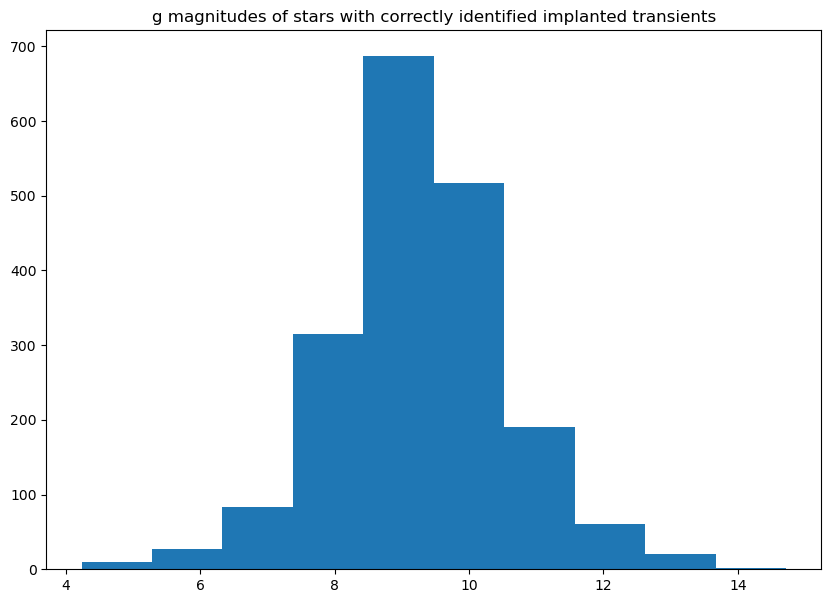

In [146]:
plt.hist(pd.to_numeric(trues_df_clean['bp_mag_ztf_g'], 'coerce'))
plt.title("g magnitudes of stars with correctly identified implanted transients")

In [228]:
fails_df_clean['intensity'].min()

0.8

In [242]:
# fails_df = pd.DataFrame(fails)
# fails_df_clean = fails_df.dropna()
fails_df_clean = fails_df.drop((fails_df[fails_df['Diff']>8]).index, axis=0) #Diff
fails_df_clean = fails_df_clean.drop((fails_df_clean[pd.to_numeric(fails_df_clean['rp_mag_ztf_ri'], 'coerce')>13]).index, axis=0) #gmag


Text(0, 0.5, 'count')

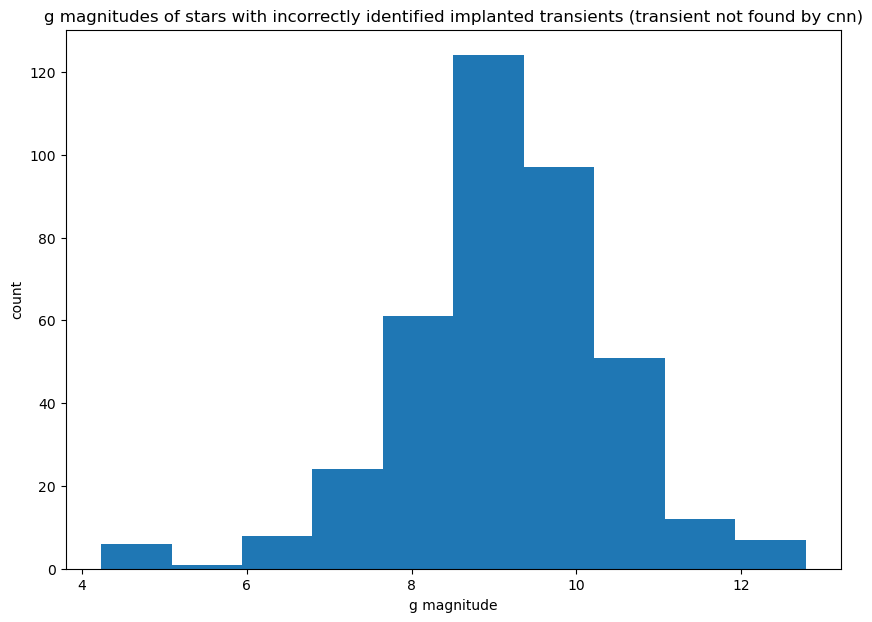

In [150]:
plt.hist(pd.to_numeric(fails_df_clean['bp_mag_ztf_g'], 'coerce'))
plt.title("g magnitudes of stars with incorrectly identified implanted transients (transient not found by cnn)")
plt.xlabel("g magnitude")
plt.ylabel("count")

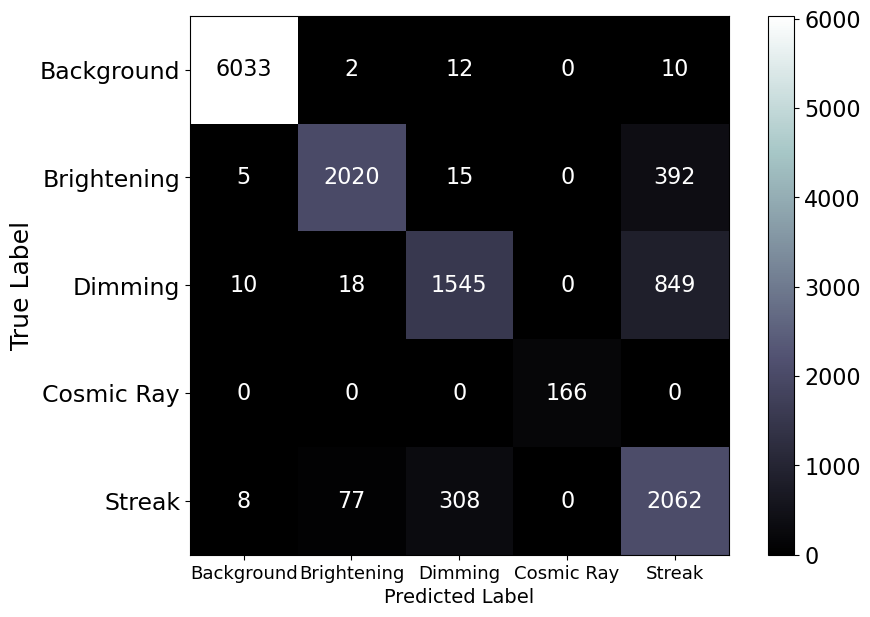

In [239]:
disp = ConfusionMatrixDisplay.from_predictions(
    targ_te,
    np.argmax(label_pred_te, axis=1),
    display_labels=["Background", "Brightening", "Dimming", "Cosmic Ray", "Streak"],
    cmap="bone",
    normalize=None,
)

# Adjust tick label size
disp.ax_.tick_params(axis="y", labelsize=17)
disp.ax_.tick_params(axis="x", labelsize=13)

# Adjust font size of numbers
for text in disp.ax_.texts:  # Access text annotations
    text.set_fontsize(16)  # Set desired font size
disp.ax_.set_xlabel("Predicted Label", fontsize=14)  # Adjust X-axis label
disp.ax_.set_ylabel("True Label", fontsize=18)  # Adjust Y-axis label

cbar = disp.im_.colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=16)  # Adjust tick label size

In [35]:
import seaborn as sns

In [47]:
trues[:,3:5]

array([[2.0, 5.0],
       [1.5, 5.0],
       [2.0, 3.0],
       ...,
       [2.0, 8.0],
       [1.5, 8.0],
       [1.5, 4.0]], dtype=object)

In [207]:
trues_df_clean

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
8476,8476.0,8476.0,ztf_20221020138241_000686_zi_c05_x_0011._4_sta...,2.0,5.0,472.0,1936.0,471.0,630.0,1.0,302.469267,32.136446,i,2054826325662132736.0,8.086595,1.7954774,7.168001,8.963478,NOT_AVAILABLE,False
111,111.0,111.0,ztf_20221017148750_000831_zi_c04_x_0017._4_sta...,2.0,3.0,1414.0,296.0,1412.0,2145.0,2.0,335.612292,58.59942,i,2200326181135910912.0,8.097496,1.2999096,7.373723,8.673633,NOT_AVAILABLE,False
683,683.0,683.0,ztf_20221020138241_000686_zi_c01_x_0018._2_sta...,10.0,8.0,1453.0,847.0,1452.0,2846.0,1.0,301.064026,30.541202,i,2030590104408453888.0,9.0276165,0.5132394,7.853382,8.366621,NOT_AVAILABLE,False
7097,7097.0,7097.0,ztf_20221020138241_000686_zi_c05_x_0009._2_sta...,1.3,5.0,1537.0,1958.0,1535.0,1528.0,2.0,301.118211,32.822502,i,2055143401649846784.0,7.1805773,1.8194284,6.255091,8.074519,NOT_AVAILABLE,False
4870,4870.0,4870.0,ztf_20221014162894_000802_zg_c01_x_0005._3_sta...,4.0,5.0,2557.0,1029.0,2556.0,2245.0,1.0,327.737731,51.390684,g,1980697805783294464.0,8.625472,1.3244753,7.881644,9.20612,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4871,4871.0,4871.0,ztf_20221017148750_000831_zi_c03_x_0009._2_sta...,1.3,3.0,308.0,350.0,307.0,2367.0,1.0,338.06903,59.493397,i,2200284193537444096.0,8.465369,0.81221485,7.971989,8.784204,NOT_AVAILABLE,False
2057,2057.0,2057.0,ztf_20221020138241_000686_zi_c04_x_0017._3_sta...,2.0,4.0,1768.0,1944.0,1768.0,764.0,0.0,294.513345,30.212453,i,2032501983363664384.0,8.402938,2.2172518,7.338659,9.555911,NOT_AVAILABLE,False
8161,8161.0,8161.0,ztf_20221014162894_000802_zg_c01_x_0014._1_sta...,2.0,8.0,1133.0,1718.0,1132.0,1589.0,1.0,329.899159,52.385971,g,1981181350379638784.0,9.546463,0.2684126,9.345552,9.613965,VARIABLE,True
4732,4732.0,4732.0,ztf_20220820237546_000798_zr_c02_x_0002._3_sta...,1.5,8.0,1166.0,420.0,1166.0,636.0,0.0,281.010571,51.879953,r,2144775349000008448.0,10.378234,0.60126877,10.003489,10.604757,NOT_AVAILABLE,False


In [206]:
np.array((trues_df_clean['intensity'],trues_df_clean['sigma'])).T

array([[ 2. ,  5. ],
       [ 2. ,  3. ],
       [10. ,  8. ],
       ...,
       [ 2. ,  8. ],
       [ 1.5,  8. ],
       [ 1.5,  4. ]])

In [231]:
trues_df_clean['intensity'].min()

0.8

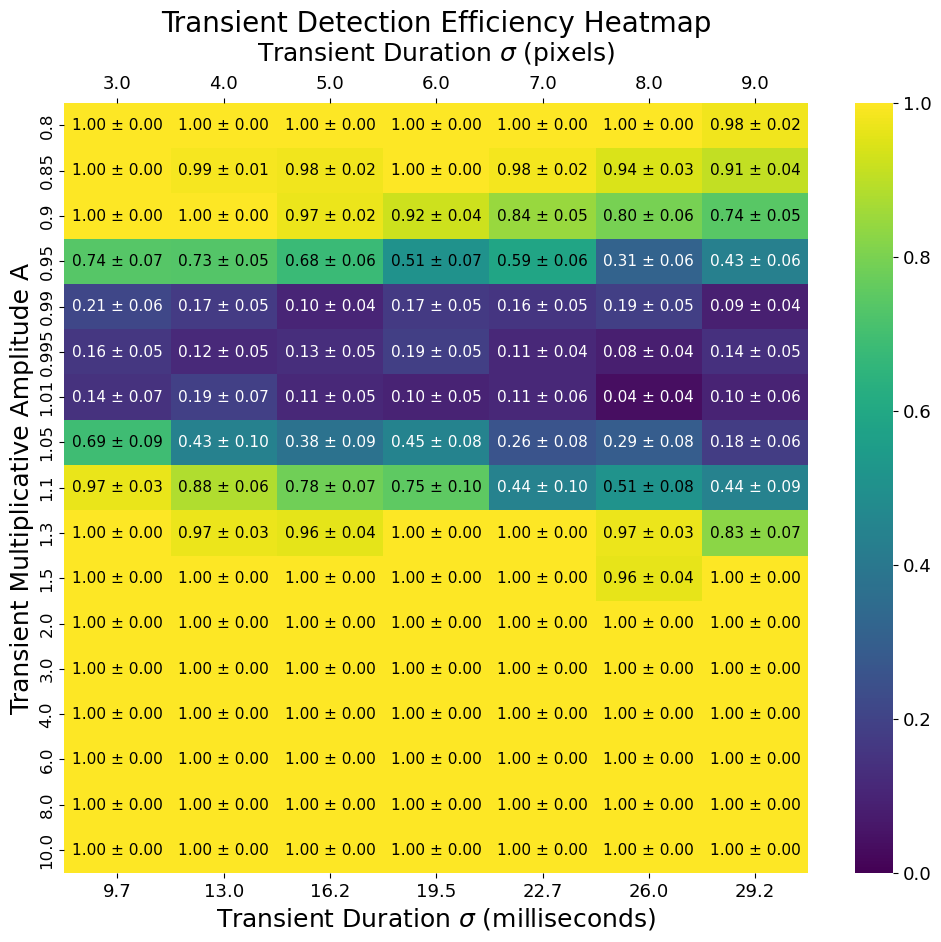

In [232]:
# Given nonlinear brightness values
brightness_values = np.unique(our_bness_te['intensity'])
length_values = np.unique(our_bness_te['sigma'])

# # Given nonlinear brightness and length values
# brightness_values = np.array([0.8, 0.9, 0.99, 1.01, 1.1, 2, 5, 10])
# length_values = np.array([1, 2, 3, 4, 5, 6, 7, 8])  # Example length values

# Create bins for brightness and length
brightness_bins = np.concatenate(
    [
        [brightness_values[0] - 0.1],
        (brightness_values[:-1] + brightness_values[1:]) / 2,
        [brightness_values[-1] + 0.1],
    ]
)

length_bins = np.concatenate(
    [
        [length_values[0] - 0.5],
        (length_values[:-1] + length_values[1:]) / 2,
        [length_values[-1] + 0.5],
    ]
)


correct_detections = np.array((trues_df_clean['intensity'],trues_df_clean['sigma'])).T  # Array of correctly detected (brightness, length)
incorrect_detections = np.array((fails_df_clean['intensity'],fails_df_clean['sigma'])).T  # Array of incorrectly detected (brightness, length)

# Create 2D histogram for correct and total detections
correct_hist, xedges, yedges = np.histogram2d(
    correct_detections[:, 0],
    correct_detections[:, 1],
    bins=[brightness_bins, length_bins],
)

total_hist, _, _ = np.histogram2d(
    np.vstack((correct_detections, incorrect_detections))[:, 0],
    np.vstack((correct_detections, incorrect_detections))[:, 1],
    bins=[brightness_bins, length_bins],
)

# Calculate efficiency
efficiency = correct_hist / total_hist

# Calculate error (using Poisson approximation)
error = np.sqrt(efficiency * (1 - efficiency) / total_hist)

# Plotting the heatmap
plt.figure(figsize=(12, 10))
bottom_ticks_values = (
    np.arange(3, len(length_values) + 3) * 10000 / 3080
)  # * (10/6.15)  # Example: double the length values
bottom_tick_labels = [f"{val:.1f}" for val in bottom_ticks_values]
heatmap = sns.heatmap(
    efficiency,
    xticklabels=bottom_tick_labels,
    yticklabels=brightness_values,
    cmap="viridis",
    annot=False,
    vmin=0,
    vmax=1,
)

# Setting the bottom axis label
ax = plt.gca()  # Get the current axis
ax.set_xlabel("Transient Duration $\sigma$ (milliseconds)", fontsize=18)  # Bottom label
ax.xaxis.set_label_position("bottom")  # Ensure the label is positioned at the bottom
ax.xaxis.tick_bottom()  # Ensure the ticks are at the bottom

# Customizing the bottom ticks
# plt.xticks(ticks=bottom_ticks_values, labels=bottom_tick_labels, fontsize=12)
plt.xticks(fontsize=12)

# Creating custom ticks and label for the top axis with different numbers
top_tick_labels = length_values
ax_top = ax.twiny()  # Create a new axis sharing the x-axis
ax_top.set_xlim(ax.get_xlim())  # Ensure the limits are shared
ax_top.set_xticks(np.arange(len(length_values)) + 0.5)  # Set tick positions for top
ax_top.set_xticklabels(top_tick_labels, fontsize=13)  # Set custom labels for top
ax_top.set_xlabel(
    "Transient Duration $\sigma$ (pixels)", fontsize=18, labelpad=10
)  # Top label

# Setting y-axis label and title
ax.set_ylabel("Transient Multiplicative Amplitude A", fontsize=18)
plt.title("Transient Detection Efficiency Heatmap", fontsize=20)

# Customizing tick positions and labels for the y-axis
plt.yticks(
    ticks=np.arange(len(brightness_values)) + 0.5, labels=brightness_values, fontsize=12
)

# Overlaying error bars and adding text annotations
for i in range(efficiency.shape[0]):
    for j in range(efficiency.shape[1]):
        if total_hist[i, j] > 0:  # Only annotate if there are detections
            # Format the annotation text
            text = f"{efficiency[i, j]:.2f} ± {error[i, j]:.2f}"
            # Add the text annotation in the center of each bin
            if efficiency[i, j]<.5:
                color="white"
            else:
                color='black'
            plt.text(
                j + 0.5,
                i + 0.5,
                text,
                ha="center",
                va="center",
                color=color,
                fontsize=11,
            )

            # Remove the black outline (spines) from all sides
for spine in ax.spines.values():
    spine.set_visible(False)

for spine in ax_top.spines.values():
    spine.set_visible(False)


# Adjust tick label size
ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=13)


# Access the colorbar and modify tick font size
cbar = heatmap.collections[0].colorbar  # Access the colorbar
cbar.ax.tick_params(labelsize=13)  # Adjust tick label size


plt.show()

In [244]:
g_stars_true = trues_df_clean[trues_df_clean['Band']=="g"]
r_stars_true = trues_df_clean[trues_df_clean['Band']=="r"]
i_stars_true = trues_df_clean[trues_df_clean['Band']=="i"]

g_stars_fail = fails_df_clean[fails_df_clean['Band']=="g"]
r_stars_fail = fails_df_clean[fails_df_clean['Band']=="r"]
i_stars_fail = fails_df_clean[fails_df_clean['Band']=="i"]

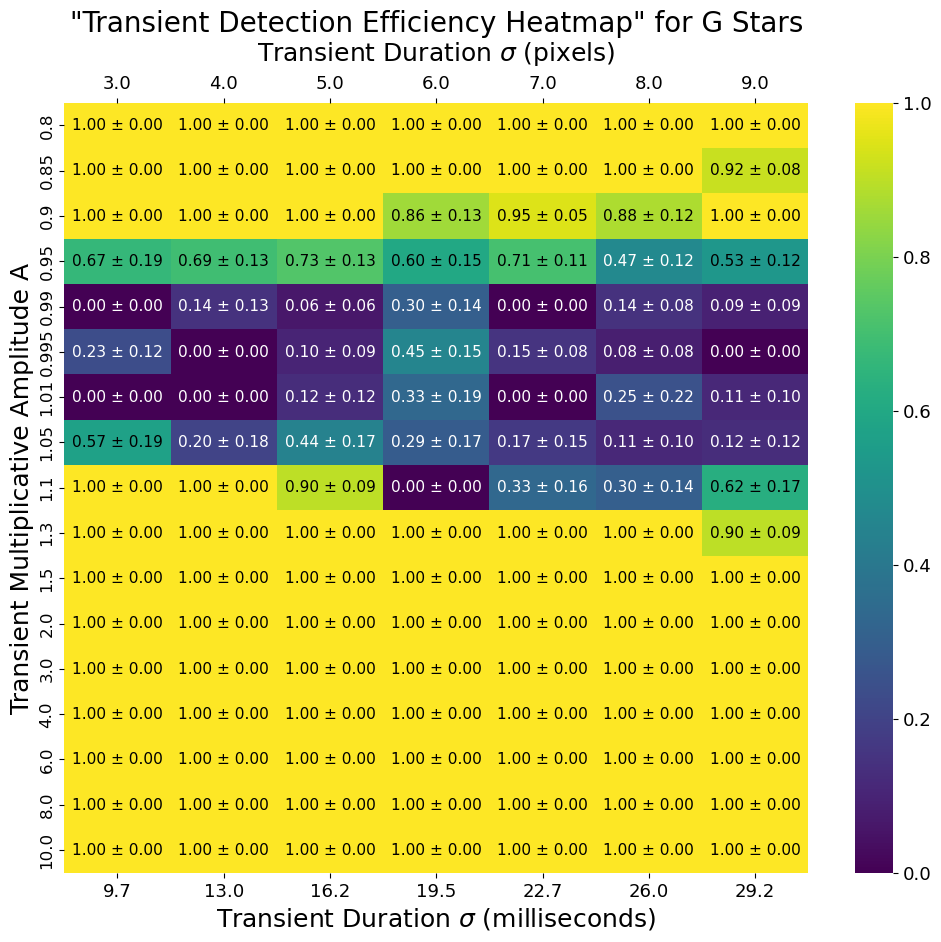

In [250]:

def create_heatmap(correct_detections,incorrect_detections,title="Transient Detection Efficiency Heatmap"):
    # Given nonlinear brightness values
    brightness_values = np.unique(our_bness_te['intensity'])
    length_values = np.unique(our_bness_te['sigma'])
    
    # # Given nonlinear brightness and length values
    # brightness_values = np.array([0.8, 0.9, 0.99, 1.01, 1.1, 2, 5, 10])
    # length_values = np.array([1, 2, 3, 4, 5, 6, 7, 8])  # Example length values
    
    # Create bins for brightness and length
    brightness_bins = np.concatenate(
        [
            [brightness_values[0] - 0.1],
            (brightness_values[:-1] + brightness_values[1:]) / 2,
            [brightness_values[-1] + 0.1],
        ]
    )
    
    length_bins = np.concatenate(
        [
            [length_values[0] - 0.5],
            (length_values[:-1] + length_values[1:]) / 2,
            [length_values[-1] + 0.5],
        ]
    )
    
    
    
    # Create 2D histogram for correct and total detections
    correct_hist, xedges, yedges = np.histogram2d(
        correct_detections[:, 0],
        correct_detections[:, 1],
        bins=[brightness_bins, length_bins],
    )
    
    total_hist, _, _ = np.histogram2d(
        np.vstack((correct_detections, incorrect_detections))[:, 0],
        np.vstack((correct_detections, incorrect_detections))[:, 1],
        bins=[brightness_bins, length_bins],
    )
    
    # Calculate efficiency
    efficiency = correct_hist / total_hist
    
    # Calculate error (using Poisson approximation)
    error = np.sqrt(efficiency * (1 - efficiency) / total_hist)
    
    # Plotting the heatmap
    plt.figure(figsize=(12, 10))
    bottom_ticks_values = (
        np.arange(3, len(length_values) + 3) * 10000 / 3080
    )  # * (10/6.15)  # Example: double the length values
    bottom_tick_labels = [f"{val:.1f}" for val in bottom_ticks_values]
    heatmap = sns.heatmap(
        efficiency,
        xticklabels=bottom_tick_labels,
        yticklabels=brightness_values,
        cmap="viridis",
        annot=False,
        vmin=0,
        vmax=1,
    )
    
    # Setting the bottom axis label
    ax = plt.gca()  # Get the current axis
    ax.set_xlabel("Transient Duration $\sigma$ (milliseconds)", fontsize=18)  # Bottom label
    ax.xaxis.set_label_position("bottom")  # Ensure the label is positioned at the bottom
    ax.xaxis.tick_bottom()  # Ensure the ticks are at the bottom
    
    # Customizing the bottom ticks
    # plt.xticks(ticks=bottom_ticks_values, labels=bottom_tick_labels, fontsize=12)
    plt.xticks(fontsize=12)
    
    # Creating custom ticks and label for the top axis with different numbers
    top_tick_labels = length_values
    ax_top = ax.twiny()  # Create a new axis sharing the x-axis
    ax_top.set_xlim(ax.get_xlim())  # Ensure the limits are shared
    ax_top.set_xticks(np.arange(len(length_values)) + 0.5)  # Set tick positions for top
    ax_top.set_xticklabels(top_tick_labels, fontsize=13)  # Set custom labels for top
    ax_top.set_xlabel(
        "Transient Duration $\sigma$ (pixels)", fontsize=18, labelpad=10
    )  # Top label
    
    # Setting y-axis label and title
    ax.set_ylabel("Transient Multiplicative Amplitude A", fontsize=18)
    plt.title(title, fontsize=20)
    
    # Customizing tick positions and labels for the y-axis
    plt.yticks(
        ticks=np.arange(len(brightness_values)) + 0.5, labels=brightness_values, fontsize=12
    )
    
    # Overlaying error bars and adding text annotations
    for i in range(efficiency.shape[0]):
        for j in range(efficiency.shape[1]):
            if total_hist[i, j] > 0:  # Only annotate if there are detections
                # Format the annotation text
                text = f"{efficiency[i, j]:.2f} ± {error[i, j]:.2f}"
                # Add the text annotation in the center of each bin
                if efficiency[i, j]<.5:
                    color="white"
                else:
                    color='black'
                plt.text(
                    j + 0.5,
                    i + 0.5,
                    text,
                    ha="center",
                    va="center",
                    color=color,
                    fontsize=11,
                )
    
                # Remove the black outline (spines) from all sides
    for spine in ax.spines.values():
        spine.set_visible(False)
    
    for spine in ax_top.spines.values():
        spine.set_visible(False)
    
    
    # Adjust tick label size
    ax.tick_params(axis="y", labelsize=12)
    ax.tick_params(axis="x", labelsize=13)
    
    
    # Access the colorbar and modify tick font size
    cbar = heatmap.collections[0].colorbar  # Access the colorbar
    cbar.ax.tick_params(labelsize=13)  # Adjust tick label size
    
    
    plt.show()

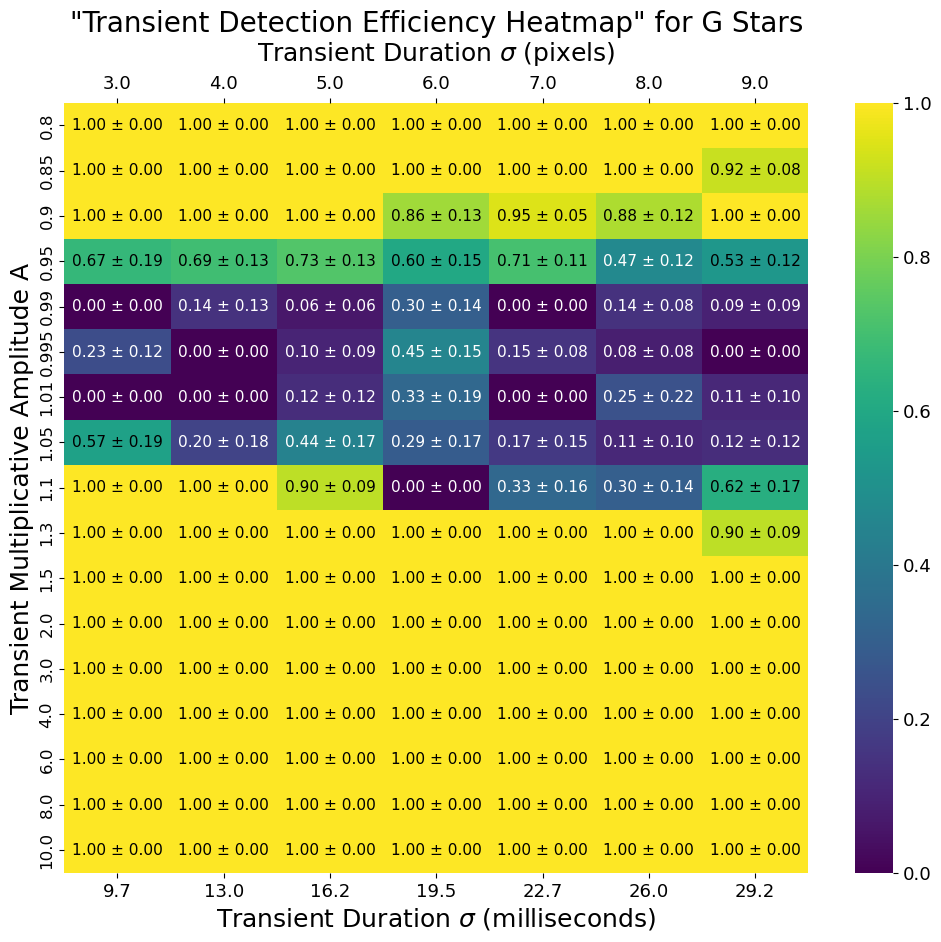

In [253]:
#for bands stars

correct_detections = np.array((g_stars_true['intensity'],g_stars_true['sigma'])).T  # Array of correctly detected (brightness, length)
incorrect_detections = np.array((g_stars_fail['intensity'],g_stars_fail['sigma'])).T  # Array of incorrectly detected (brightness, length)

create_heatmap(correct_detections,incorrect_detections, title='"Transient Detection Efficiency Heatmap" for G Stars')

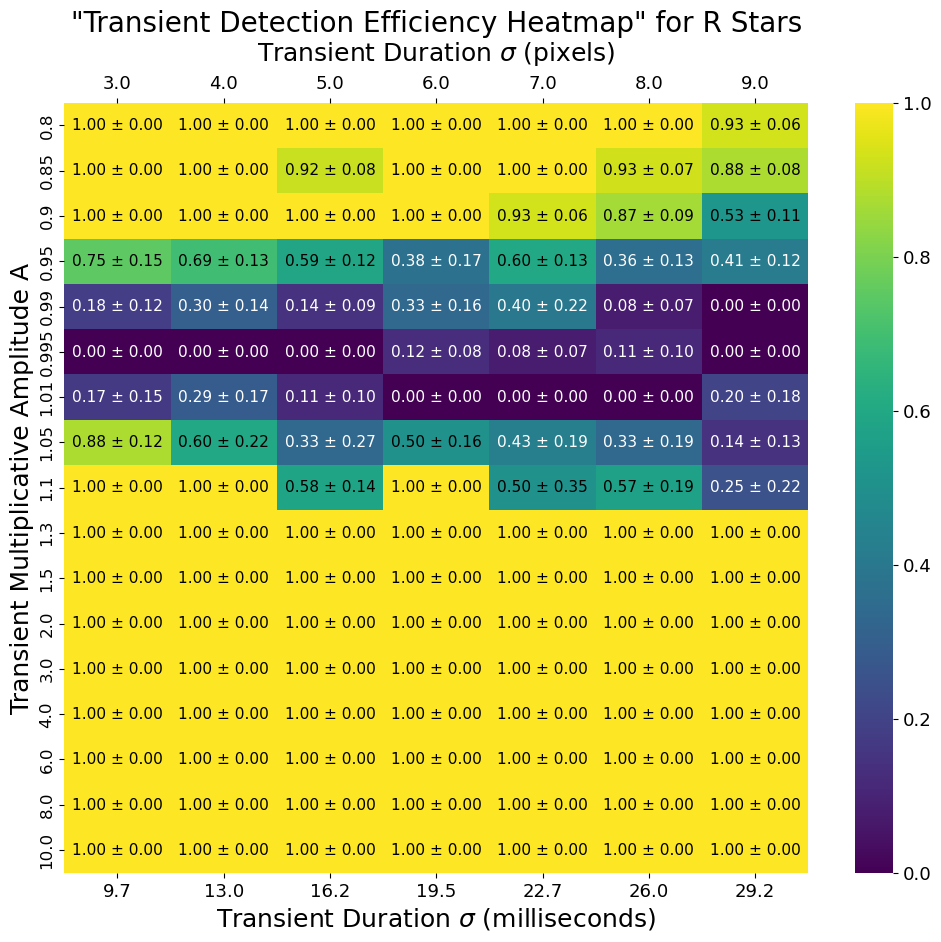

In [254]:
#for bands stars

correct_detections = np.array((r_stars_true['intensity'],r_stars_true['sigma'])).T  # Array of correctly detected (brightness, length)
incorrect_detections = np.array((r_stars_fail['intensity'],r_stars_fail['sigma'])).T  # Array of incorrectly detected (brightness, length)

create_heatmap(correct_detections,incorrect_detections, title='"Transient Detection Efficiency Heatmap" for R Stars')

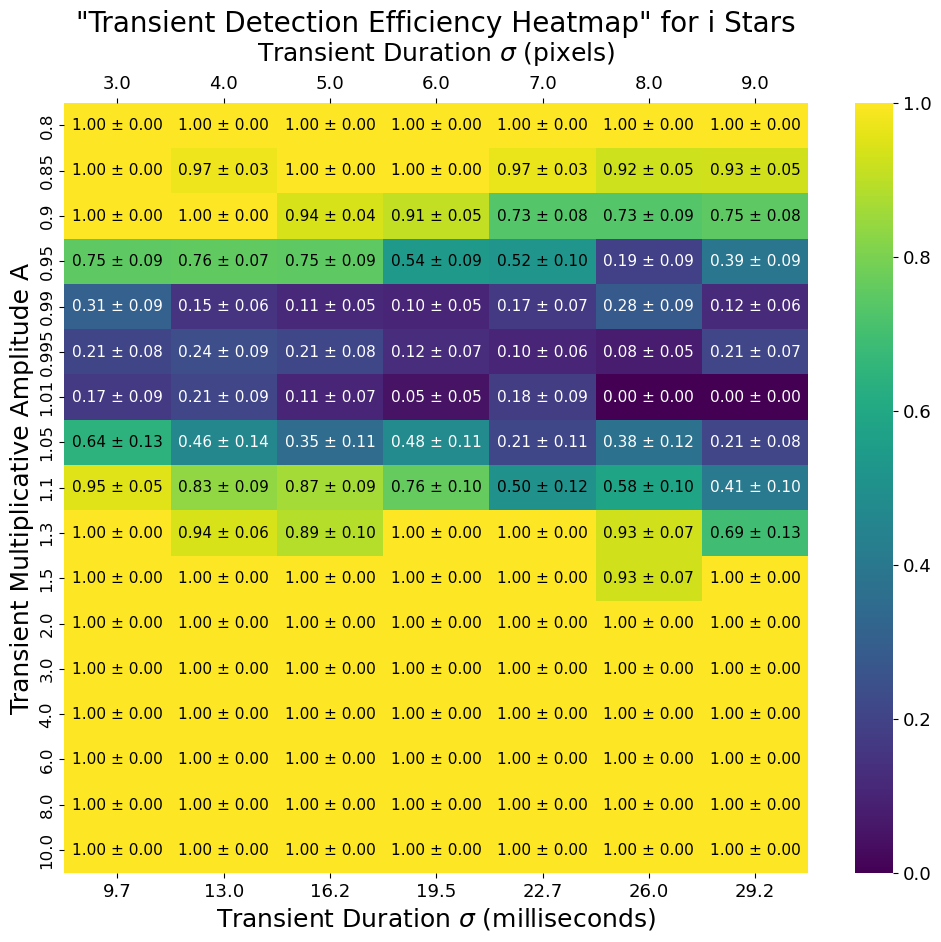

In [256]:
#for bands stars

correct_detections = np.array((i_stars_true['intensity'],i_stars_true['sigma'])).T  # Array of correctly detected (brightness, length)
incorrect_detections = np.array((i_stars_fail['intensity'],i_stars_fail['sigma'])).T  # Array of incorrectly detected (brightness, length)

create_heatmap(correct_detections,incorrect_detections, title='"Transient Detection Efficiency Heatmap" for i Stars')

In [257]:
g_stars_true

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
4870,4870.0,4870.0,ztf_20221014162894_000802_zg_c01_x_0005._3_sta...,4.00,5.0,2557.0,1029.0,2556.0,2245.0,1.0,327.737731,51.390684,g,1980697805783294464.0,8.625472,1.3244753,7.881644,9.20612,NOT_AVAILABLE,False
3405,NaN,NaN,ztf_20221014162894_000802_zg_c01_x_0010._4_sta...,0.90,5.0,1736.0,1381.0,1735.0,1174.0,1.0,329.5242203280381,51.621660013980964,g,1.980304455501248e+18,NaN,NaN,8.758804321289062,8.84275,NaN,NaN
585,585.0,585.0,ztf_20221014162894_000802_zg_c03_x_0000._3_sta...,1.10,5.0,1013.0,1247.0,1012.0,653.0,1.0,322.47757,51.875271,g,2172465759071547904.0,9.3419485,0.45370865,9.029671,9.483379,NOT_AVAILABLE,False
1770,NaN,NaN,ztf_20221014162894_000802_zg_c01_x_0012._4_sta...,0.80,9.0,106.0,2969.0,106.0,2419.0,0.0,330.2108146341151,51.23646013304083,g,1.980225977857024e+18,NaN,NaN,8.676165580749512,8.733712,NaN,NaN
5244,5244.0,5244.0,ztf_20221014162894_000802_zg_c02_x_0022._2_sta...,8.00,4.0,1670.0,2019.0,1677.0,779.0,7.0,325.194297,52.748504,g,2173323549958832128.0,10.703177,0.23847866,10.544333,10.782811,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7674,7674.0,7674.0,ztf_20221014162894_000802_zg_c01_x_0011._1_sta...,8.00,5.0,3039.0,2973.0,3039.0,111.0,0.0,329.070778,52.842682,g,1981352496239643904.0,9.402663,1.3787165,8.645198,10.023914,NOT_AVAILABLE,False
5018,5018.0,5018.0,ztf_20221014162894_000802_zg_c01_x_0011._3_sta...,2.00,4.0,634.0,2783.0,633.0,2878.0,1.0,328.584272,51.182283,g,1980644376389140992.0,9.537248,0.30429268,9.328971,9.633264,NOT_AVAILABLE,False
94,94.0,94.0,ztf_20221014162894_000802_zg_c02_x_0028._1_sta...,3.00,8.0,1918.0,908.0,1916.0,215.0,2.0,326.518767,52.887895,g,2173214148551505920.0,7.713946,1.4049854,6.944537,8.349523,NOT_AVAILABLE,False
6178,NaN,NaN,ztf_20221014162894_000802_zg_c02_x_0011._2_sta...,0.85,4.0,940.0,714.0,938.0,2385.0,2.0,325.52353818948967,52.292445207292864,g,2.1730988029085688e+18,NaN,NaN,6.1590256690979,7.262315,NaN,NaN


In [262]:
g_stars_true[pd.to_numeric( g_stars_true['bp_mag_ztf_g'], 'coerce')>7]

,Unnamed: 0.1,Unnamed: 0,filename,intensity,sigma,streak_x_val,center_value_y,closest_x,closest_y,Diff,star_ra,star_dec,Band,gaia_source_id,g_mag,bp_rp,rp_mag_ztf_ri,bp_mag_ztf_g,variability,in_vari_summary
4870,4870.0,4870.0,ztf_20221014162894_000802_zg_c01_x_0005._3_sta...,4.00,5.0,2557.0,1029.0,2556.0,2245.0,1.0,327.737731,51.390684,g,1980697805783294464.0,8.625472,1.3244753,7.881644,9.20612,NOT_AVAILABLE,False
3405,NaN,NaN,ztf_20221014162894_000802_zg_c01_x_0010._4_sta...,0.90,5.0,1736.0,1381.0,1735.0,1174.0,1.0,329.5242203280381,51.621660013980964,g,1.980304455501248e+18,NaN,NaN,8.758804321289062,8.84275,NaN,NaN
585,585.0,585.0,ztf_20221014162894_000802_zg_c03_x_0000._3_sta...,1.10,5.0,1013.0,1247.0,1012.0,653.0,1.0,322.47757,51.875271,g,2172465759071547904.0,9.3419485,0.45370865,9.029671,9.483379,NOT_AVAILABLE,False
1770,NaN,NaN,ztf_20221014162894_000802_zg_c01_x_0012._4_sta...,0.80,9.0,106.0,2969.0,106.0,2419.0,0.0,330.2108146341151,51.23646013304083,g,1.980225977857024e+18,NaN,NaN,8.676165580749512,8.733712,NaN,NaN
5244,5244.0,5244.0,ztf_20221014162894_000802_zg_c02_x_0022._2_sta...,8.00,4.0,1670.0,2019.0,1677.0,779.0,7.0,325.194297,52.748504,g,2173323549958832128.0,10.703177,0.23847866,10.544333,10.782811,NOT_AVAILABLE,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7674,7674.0,7674.0,ztf_20221014162894_000802_zg_c01_x_0011._1_sta...,8.00,5.0,3039.0,2973.0,3039.0,111.0,0.0,329.070778,52.842682,g,1981352496239643904.0,9.402663,1.3787165,8.645198,10.023914,NOT_AVAILABLE,False
5018,5018.0,5018.0,ztf_20221014162894_000802_zg_c01_x_0011._3_sta...,2.00,4.0,634.0,2783.0,633.0,2878.0,1.0,328.584272,51.182283,g,1980644376389140992.0,9.537248,0.30429268,9.328971,9.633264,NOT_AVAILABLE,False
94,94.0,94.0,ztf_20221014162894_000802_zg_c02_x_0028._1_sta...,3.00,8.0,1918.0,908.0,1916.0,215.0,2.0,326.518767,52.887895,g,2173214148551505920.0,7.713946,1.4049854,6.944537,8.349523,NOT_AVAILABLE,False
6178,NaN,NaN,ztf_20221014162894_000802_zg_c02_x_0011._2_sta...,0.85,4.0,940.0,714.0,938.0,2385.0,2.0,325.52353818948967,52.292445207292864,g,2.1730988029085688e+18,NaN,NaN,6.1590256690979,7.262315,NaN,NaN


In [269]:
print(len(bright_true),len(bright_fail),len(dim_true),len(dim_fail))

1443 562 1898 665


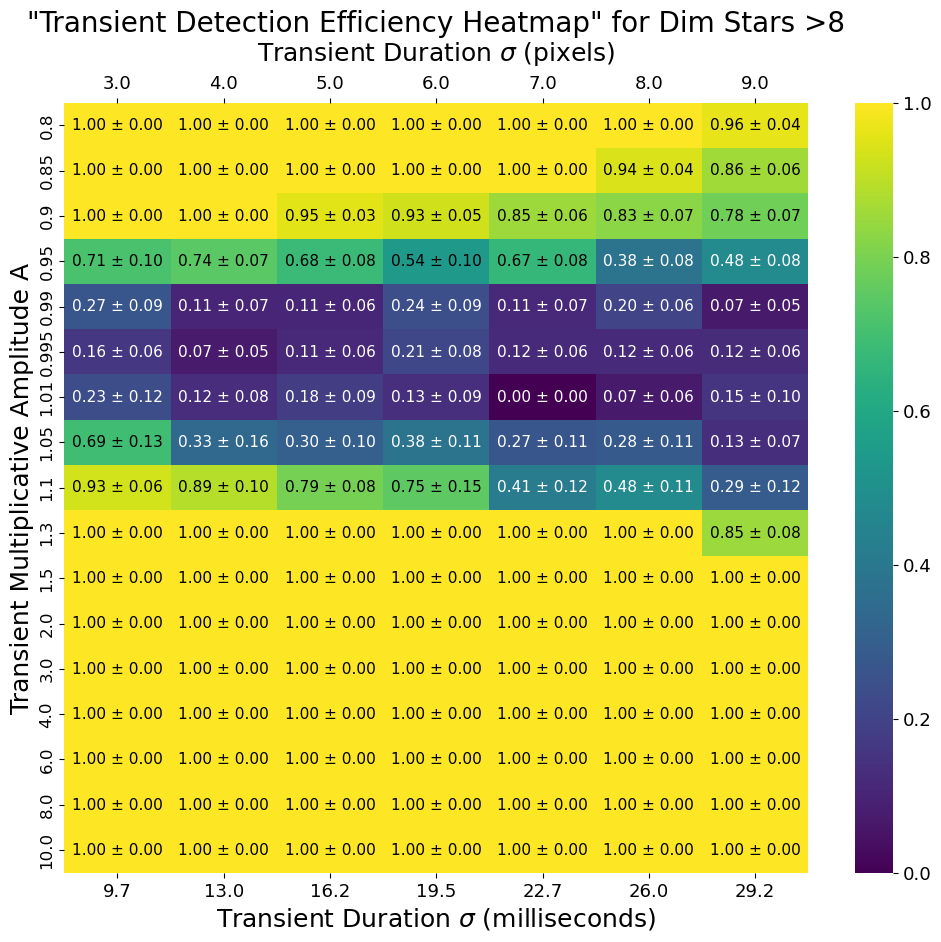

In [270]:
#for bands stars

g_stars_true = trues_df_clean[trues_df_clean['Band']=="g"]
r_stars_true = trues_df_clean[trues_df_clean['Band']=="r"]
i_stars_true = trues_df_clean[trues_df_clean['Band']=="i"]

g_stars_fail = fails_df_clean[fails_df_clean['Band']=="g"]
r_stars_fail = fails_df_clean[fails_df_clean['Band']=="r"]
i_stars_fail = fails_df_clean[fails_df_clean['Band']=="i"]

dim_true = pd.concat((g_stars_true[pd.to_numeric( g_stars_true['bp_mag_ztf_g'], 'coerce')>8], 
                     i_stars_true[pd.to_numeric( i_stars_true['rp_mag_ztf_ri'],'coerce')>8],
                     r_stars_true[pd.to_numeric( r_stars_true['rp_mag_ztf_ri'],'coerce')>8]))


dim_fail = pd.concat((g_stars_fail[pd.to_numeric( g_stars_fail['bp_mag_ztf_g'], 'coerce')>8], 
                     i_stars_fail[pd.to_numeric( i_stars_fail['rp_mag_ztf_ri'],'coerce')>8],
                     r_stars_fail[pd.to_numeric( r_stars_fail['rp_mag_ztf_ri'],'coerce')>8]))

bright_true = pd.concat((g_stars_true[pd.to_numeric( g_stars_true['bp_mag_ztf_g'], 'coerce')<8], 
                     i_stars_true[pd.to_numeric( i_stars_true['rp_mag_ztf_ri'],'coerce')<8],
                     r_stars_true[pd.to_numeric( r_stars_true['rp_mag_ztf_ri'],'coerce')<8]))


bright_fail = pd.concat((g_stars_fail[pd.to_numeric( g_stars_fail['bp_mag_ztf_g'], 'coerce')<8], 
                     i_stars_fail[pd.to_numeric( i_stars_fail['rp_mag_ztf_ri'],'coerce')<8],
                     r_stars_fail[pd.to_numeric( r_stars_fail['rp_mag_ztf_ri'],'coerce')<8]))



correct_detections = np.array((dim_true['intensity'],dim_true['sigma'])).T  # Array of correctly detected (brightness, length)
incorrect_detections = np.array((dim_fail['intensity'],dim_fail['sigma'])).T  # Array of incorrectly detected (brightness, length)

create_heatmap(correct_detections,incorrect_detections, title='"Transient Detection Efficiency Heatmap" for Dim Stars >8')

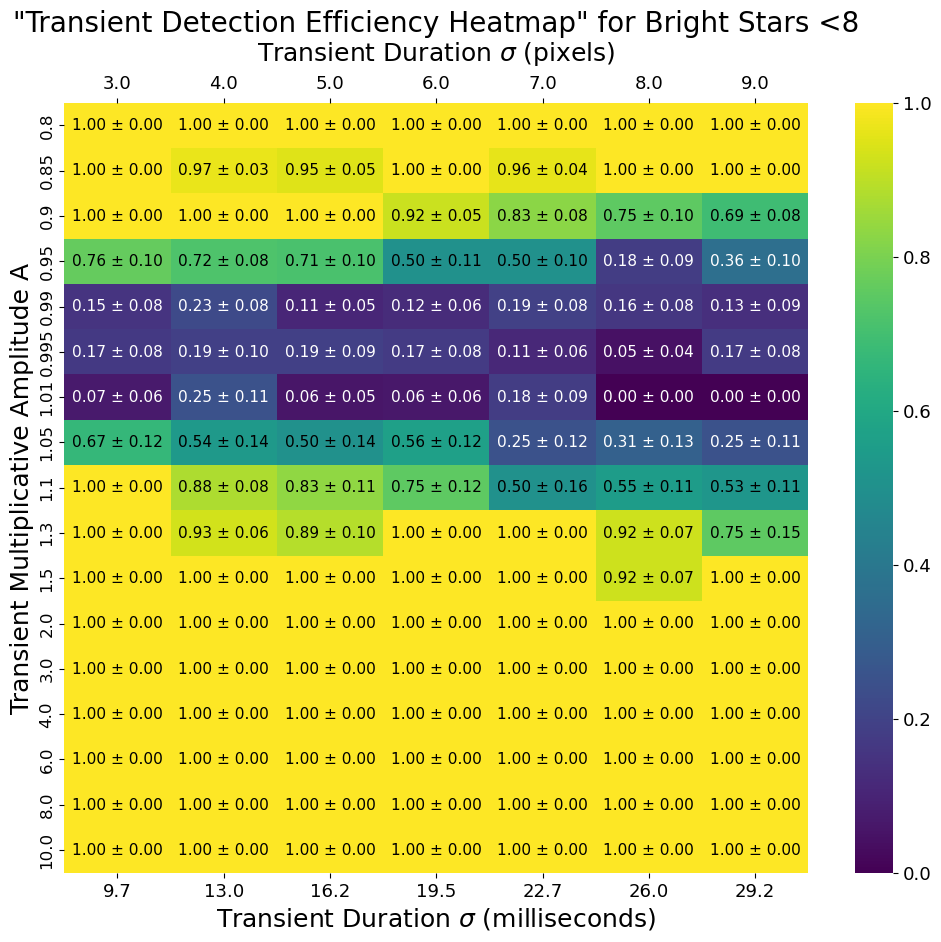

In [271]:
correct_detections = np.array((bright_true['intensity'],bright_true['sigma'])).T  # Array of correctly detected (brightness, length)
incorrect_detections = np.array((bright_fail['intensity'],bright_fail['sigma'])).T  # Array of incorrectly detected (brightness, length)

create_heatmap(correct_detections,incorrect_detections, title='"Transient Detection Efficiency Heatmap" for Bright Stars <8')